In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2  # CHỈ dùng để đọc ảnh và trong ô ĐỐI CHIẾU

In [2]:
# Sử dụng hàm convolve2d của Gấm
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

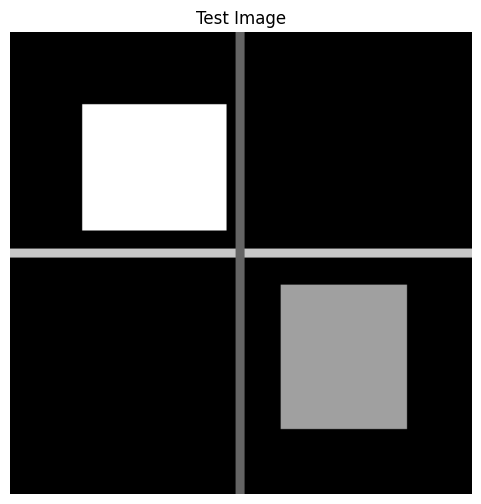

In [3]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [4]:
 
# Sobel edge detection

img_float = img_demo.astype(np.float64)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên cần lật kernel
sobel_x_conv = np.flip(sobel_x, axis=(0, 1))
sobel_y_conv = np.flip(sobel_y, axis=(0, 1))

gx = convolve2d(
    img_float, sobel_x_conv, padding="reflect"
)

gy = convolve2d(
    img_float, sobel_y_conv, padding="reflect"
)

edge_magnitude = np.sqrt(gx**2 + gy**2)

edge_direction = np.degrees(
    np.arctan2(gy, gx)
)

print("Sobel completed!")
print("gx:", gx.shape)
print("gy:", gy.shape)
 

Sobel completed!
gx: (256, 256)
gy: (256, 256)


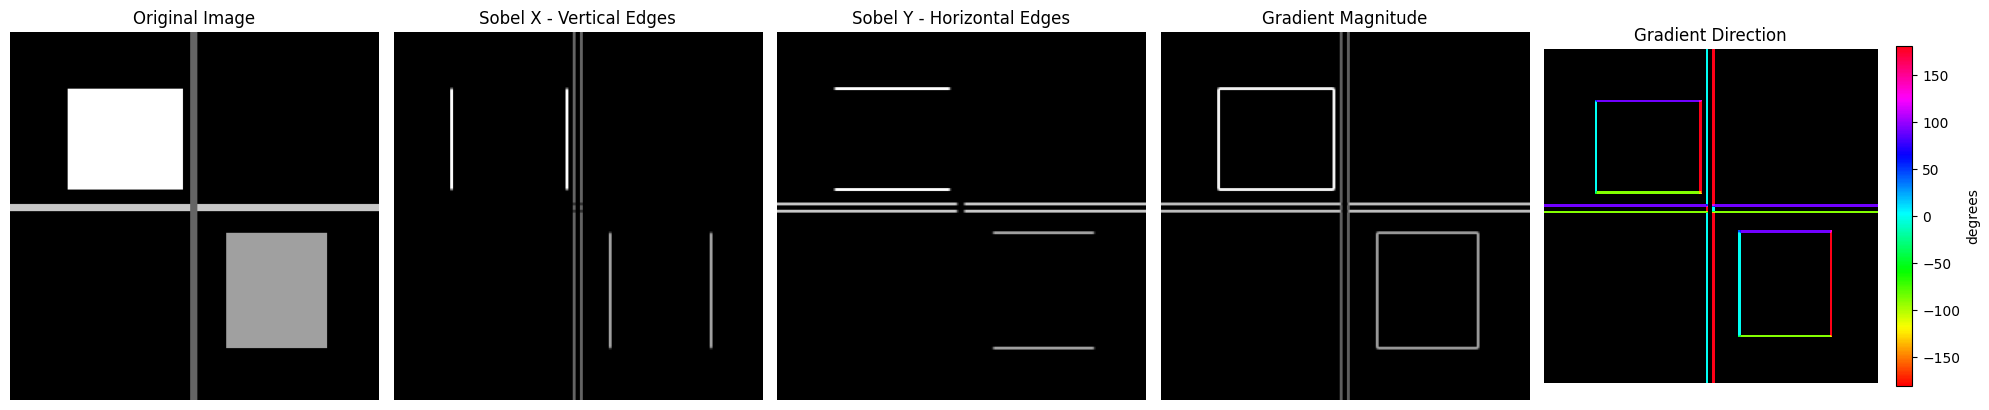

In [5]:
 
# Visualize Sobel edge detection

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

axes[0].imshow(img_demo, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(np.abs(gx), cmap="gray")
axes[1].set_title("Sobel X - Vertical Edges")

axes[2].imshow(np.abs(gy), cmap="gray")
axes[2].set_title("Sobel Y - Horizontal Edges")

axes[3].imshow(edge_magnitude, cmap="gray")
axes[3].set_title("Gradient Magnitude")

# Chỉ tô màu hướng ở pixel có cạnh; vùng phẳng (gx = gy = 0) để đen
direction_display = np.where(edge_magnitude > 0, edge_direction, np.nan)
direction_cmap = plt.get_cmap("hsv").copy()
direction_cmap.set_bad("black")
im = axes[4].imshow(direction_display, cmap=direction_cmap, vmin=-180, vmax=180,
                    interpolation="nearest")
axes[4].set_title("Gradient Direction")
fig.colorbar(im, ax=axes[4], fraction=0.046, label="degrees")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Nhận xét Sobel:**
- Sobel X phản ứng với thay đổi cường độ theo chiều ngang nên chỉ hiện các **cạnh dọc** (mép trái/phải hình chữ nhật, vạch dọc); Sobel Y ngược lại chỉ hiện **cạnh ngang**.
- Độ lớn gradient $\sqrt{g_x^2 + g_y^2}$ gộp cả hai hướng nên ra đủ viền. Hình chữ nhật trắng (255) cho viền sáng hơn hình xám (160) vì bước nhảy cường độ lớn hơn.
- Hướng gradient chỉ từ tối sang sáng: mép trái hình sáng ≈ 0°, mép phải ≈ ±180°, mép trên ≈ −90°, mép dưới ≈ 90°. Vùng phẳng không có hướng nên để đen.

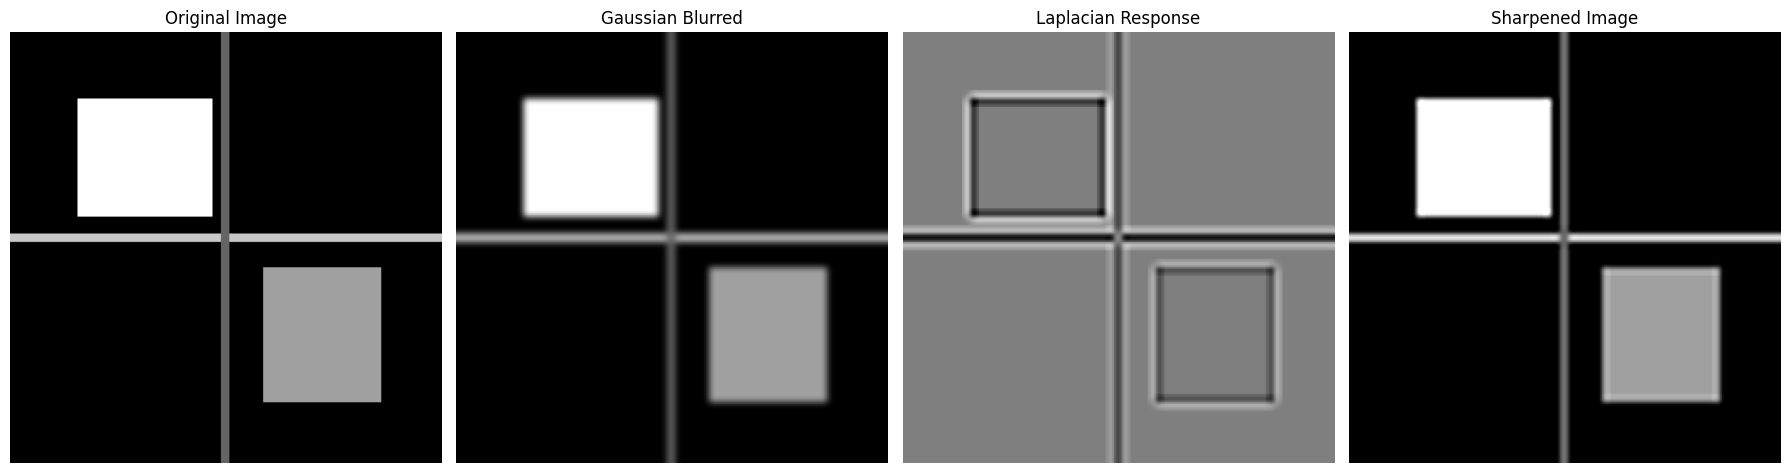

In [6]:
# Convert original image to float64
img_float = img_demo.astype(np.float64)

# Kernel Gauss tự viết, làm mờ bằng convolve2d của nhóm
def gaussian_kernel(size, sigma):
    r = size // 2
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
    return kernel / kernel.sum()

# Blur the image first to make the sharpening effect more visible
img_blurred = convolve2d(
    img_float,
    gaussian_kernel(9, 2.0),
    padding="reflect"
)

# 4-neighbor Laplacian kernel
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian to the blurred image
laplacian = convolve2d(
    img_blurred,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the blurred image
alpha = 3.0
sharpened_float = img_blurred - alpha * laplacian

# Clip to valid image range
sharpened = np.clip(
    np.round(sharpened_float), 0, 255
).astype(np.uint8)

# Convert for display
img_blurred_display = np.clip(
    np.round(img_blurred), 0, 255
).astype(np.uint8)

# Kéo giãn quanh mức xám 127.5 theo giá trị tuyệt đối lớn nhất để thấy rõ viền
laplacian_display = np.clip(
    127.5 + 127.5 * laplacian / np.abs(laplacian).max(), 0, 255
).astype(np.uint8)

# Compare original, blurred, Laplacian and sharpened images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    img_blurred_display, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Gaussian Blurred")

axes[2].imshow(
    laplacian_display, cmap="gray", vmin=0, vmax=255
)
axes[2].set_title("Laplacian Response")

axes[3].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

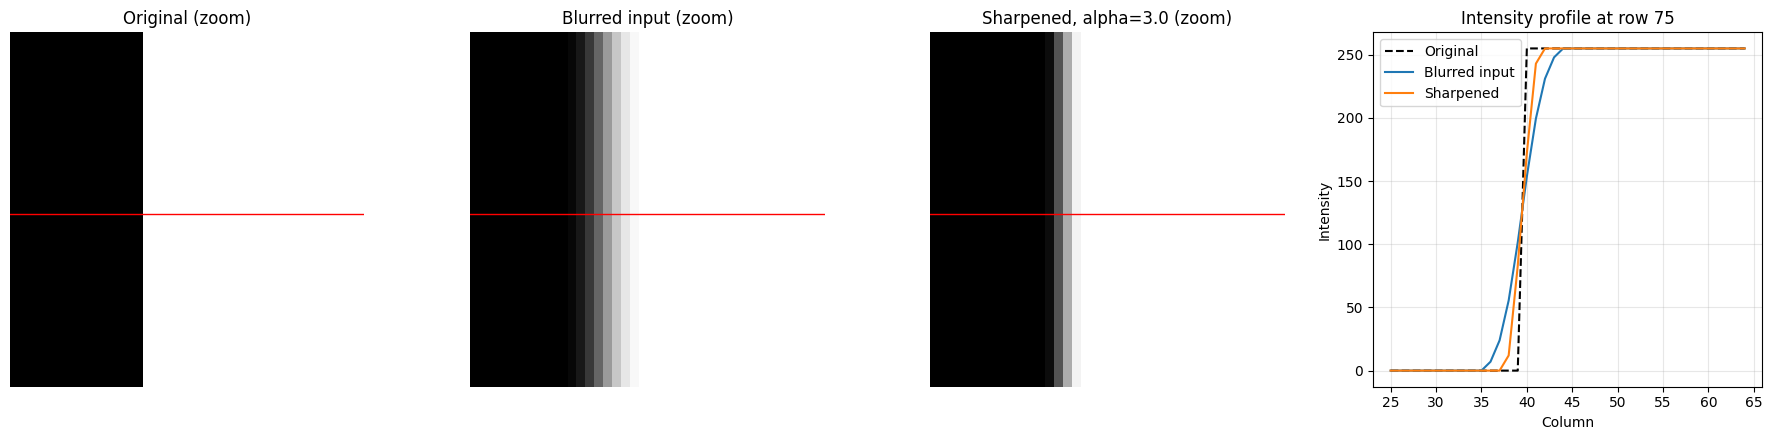

Edge width - blurred:   4 px
Edge width - sharpened: 2 px


In [7]:
# Phóng to vùng cạnh để so sánh gốc / mờ / sắc nét
r0, r1, c0, c1 = 55, 95, 25, 65   # vùng quanh cạnh trái của hình chữ nhật sáng
row = 75                          # hàng dùng để vẽ mặt cắt cường độ

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for ax, im, title in zip(
    axes[:3],
    [img_demo, img_blurred_display, sharpened],
    ["Original (zoom)", "Blurred input (zoom)", f"Sharpened, alpha={alpha} (zoom)"]
):
    ax.imshow(im[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=255,
              interpolation="nearest")
    ax.axhline(row - r0, color="red", linewidth=1)
    ax.set_title(title)
    ax.axis("off")

cols = np.arange(c0, c1)
axes[3].plot(cols, img_demo[row, c0:c1], "k--", label="Original")
axes[3].plot(cols, img_blurred[row, c0:c1], label="Blurred input")
axes[3].plot(cols, sharpened[row, c0:c1], label="Sharpened")
axes[3].set_xlabel("Column")
axes[3].set_ylabel("Intensity")
axes[3].set_title(f"Intensity profile at row {row}")
axes[3].legend()
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Độ rộng vùng chuyển (pixel có cường độ 10%–90%) càng nhỏ thì cạnh càng sắc
def edge_width(profile):
    return int(np.sum((profile > 25.5) & (profile < 229.5)))

print("Edge width - blurred:  ", edge_width(img_blurred[row, c0:c1]), "px")
print("Edge width - sharpened:", edge_width(sharpened[row, c0:c1]), "px")

**Nhận xét làm sắc nét:**
- Laplacian bằng 0 ở vùng phẳng và đổi dấu hai bên cạnh, nên $I - \alpha \nabla^2 I$ kéo phía tối tối hơn, phía sáng sáng hơn → cạnh dốc lại (độ rộng vùng chuyển giảm từ 4 px còn 2 px).
- Làm sắc nét không khôi phục được chi tiết đã mất do làm mờ, chỉ làm tăng tương phản tại cạnh. Với cạnh 0 → 255, phần vọt lố bị cắt ở 0 và 255 nên không thấy trên mặt cắt.
- $\alpha$ càng lớn cạnh càng sắc nhưng càng dễ sinh viền sáng/tối giả (vọt lố) và khuếch đại nhiễu.

In [8]:
# Kiểm tra kích thước, kiểu dữ liệu và kết quả

# 1. Kiểm tra các biến đầu vào đã tồn tại chưa
required_vars = [
    "img_demo",
    "gx",
    "gy",
    "edge_magnitude",
    "edge_direction",
    "laplacian",
    "sharpened"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("ERROR: Các biến chưa được tạo:", missing_vars)
    print("Hãy chạy lại các cell tạo ảnh, Sobel và Laplacian ở phía trên.")
else:
    # 2. In kích thước và kiểu dữ liệu
    print("Original image:", img_demo.shape, img_demo.dtype)
    print("Sobel X:", gx.shape, gx.dtype)
    print("Sobel Y:", gy.shape, gy.dtype)
    print("Gradient magnitude:", edge_magnitude.shape,
          edge_magnitude.dtype)
    print("Gradient direction:", edge_direction.shape,
          edge_direction.dtype)
    print("Laplacian:", laplacian.shape, laplacian.dtype)
    print("Sharpened image:", sharpened.shape, sharpened.dtype)

    # 3. Thống kê gradient
    print("\nMaximum gradient magnitude:",
          float(np.max(edge_magnitude)))

    print("Number of pixels with nonzero gradient:",
          int(np.count_nonzero(edge_magnitude)))

    # 4. Kiểm tra các đầu ra có cùng kích thước không
    all_shapes_match = (
        img_demo.shape == gx.shape
        == gy.shape
        == edge_magnitude.shape
        == edge_direction.shape
        == laplacian.shape
        == sharpened.shape
    )

    print("All output shapes match:", all_shapes_match)

    # 5. Kiểm tra giá trị không hợp lệ
    arrays_to_check = {
        "gx": gx,
        "gy": gy,
        "edge_magnitude": edge_magnitude,
        "edge_direction": edge_direction,
        "laplacian": laplacian,
        "sharpened": sharpened
    }

    for name, array in arrays_to_check.items():
        print(
            f"{name} contains NaN/Inf:",
            bool(np.any(~np.isfinite(array)))
        )


Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256) float64
Gradient direction: (256, 256) float64
Laplacian: (256, 256) float64
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
gx contains NaN/Inf: False
gy contains NaN/Inf: False
edge_magnitude contains NaN/Inf: False
edge_direction contains NaN/Inf: False
laplacian contains NaN/Inf: False
sharpened contains NaN/Inf: False


# KT3 – Bỏ phiếu Hough: `hough_accumulate`, `find_peaks`  _(Tấn Lên)_

Theo Computer_Vision_40.pdf, mục 4.1, 4.4–4.6.

**Quy ước** (giống ảnh thử của Gấm và `hough_multiscale` của Hiệp):
- Đường thẳng: $\rho = x\cos\theta + y\sin\theta$, gốc tọa độ ở góc trên trái, $x$ = cột, $y$ = hàng.
- Mặc định $\theta \in [0, \pi)$ (180 giá trị), $\rho \in [-D, D]$ với $D$ = đường chéo ảnh, bước 1 px.
- Hai cặp $(\rho, \theta)$ và $(-\rho, \theta + \pi)$ là cùng một đường → cột $\theta$ cuối nối với cột $\theta = 0$ khi lật dấu $\rho$ (mục 4.3, bẫy quấn vòng).

**Giao diện** (theo đặc tả mục 4.6; các tham số có giá trị mặc định là nhóm thêm cho tiện gọi):
- `hough_accumulate(edges, theta_range=(0, π), rho_range=None, n_theta=180, n_rho=None, grad_dir=None, delta_deg=None)` → `(A, thetas, rhos)`, với `A[i, j]` là số phiếu của $(\rho_i, \theta_j)$.
  - `theta_range` tính bằng radian, lấy `n_theta` giá trị cách đều, không lấy đầu mút cuối.
  - `rho_range` lấy `n_rho` giá trị cách đều, có cả hai đầu mút.
  - Khi truyền `grad_dir` (radian), mỗi điểm cạnh chỉ bỏ phiếu cho các $\theta$ lệch không quá `delta_deg` **độ** so với hướng gradient, so sánh theo modulo 180° (mục 4.4). Nếu `delta_deg=None` thì dùng 15°, trong khoảng 5°–15° tài liệu gợi ý.
- `find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0, thetas=None, rhos=None)` → danh sách `(rho, theta, votes)` sắp giảm dần theo `votes`.
  - Đặc tả chỉ có `A` nên nhóm thêm `thetas`, `rhos` (tùy chọn, đặt sau cùng) để đổi chỉ số ô ra giá trị $(\rho, \theta)$. Nếu không truyền thì trả về chỉ số ô.
  - Chỉ quấn vòng $\theta$ khi có `thetas`, `rhos`, lưới phủ đúng $[0, \pi)$ và trục $\rho$ đối xứng.

**Quy ước của nhóm cho `find_peaks`** (tài liệu mục 4.5 chỉ ghi "tích chập với nhân Gauss nhỏ, σ ≈ 1 ô", không ghi làm mờ theo trục nào, cũng không ghi `votes` lấy trước hay sau làm mờ):
- `smooth_sigma` là độ lệch chuẩn Gauss **theo trục $\rho$**, tính bằng ô tích lũy; `smooth_sigma=0` là không làm mờ. Đây là **lựa chọn của nhóm**: làm mờ theo $\rho$ đủ để gom phiếu bị chẻ sang ô $\rho$ kề nhau, còn làm mờ thêm theo $\theta$ kéo lệch đỉnh của đoạn ngắn. Phần so sánh hai cách nằm ở ô kiểm thử bên dưới.
- `votes` là **điểm tích lũy sau làm mờ**: giá trị tại đỉnh trên bảng đã làm mờ (số thực). Khi `smooth_sigma=0`, đó là số phiếu gốc. Danh sách đỉnh sắp giảm dần theo chính giá trị này.
- Triệt phi cực đại: lặp lấy ô lớn nhất → xóa hình vuông bán kính `nms_radius` ô quanh nó → lấy ô lớn tiếp theo. Kết quả là chỉ giữ đỉnh trội trong bán kính cho trước (mục 4.5).

## KT3 – Hàm tự viết

In [9]:
def hough_accumulate(edges, theta_range=(0, np.pi), rho_range=None,
                     n_theta=180, n_rho=None, grad_dir=None, delta_deg=None):
    """Bỏ phiếu vào mảng tích lũy. Nếu grad_dir khác None, chỉ bỏ phiếu
    trong dải +/- delta_deg (độ) quanh hướng gradient.
    Trả về (A, thetas, rhos), A có kích thước (n_rho, n_theta)."""
    edges = np.asarray(edges)
    if edges.ndim != 2:
        raise ValueError("edges phải là ảnh hai chiều")

    h, w = edges.shape
    ys, xs = np.nonzero(edges)

    # Trục theta: n_theta giá trị cách đều trong [theta_min, theta_max)
    theta_min, theta_max = theta_range
    if int(n_theta) != n_theta or n_theta < 1 or not theta_min < theta_max:
        raise ValueError("theta_range, n_theta không hợp lệ")
    n_theta = int(n_theta)
    thetas = theta_min + np.arange(n_theta) * (theta_max - theta_min) / n_theta

    # Trục rho: mặc định [-D, D] với D = đường chéo ảnh, bước 1 px
    if rho_range is None:
        D = np.ceil(np.hypot(h - 1, w - 1))
        rho_range = (-D, D)
    rho_min, rho_max = rho_range
    if n_rho is None:
        n_rho = int(round(rho_max - rho_min)) + 1
    if int(n_rho) != n_rho or n_rho < 2 or not rho_min < rho_max:
        raise ValueError("rho_range, n_rho không hợp lệ")
    n_rho = int(n_rho)
    rhos = np.linspace(rho_min, rho_max, n_rho)
    rho_step = (rho_max - rho_min) / (n_rho - 1)

    if grad_dir is not None:
        grad_dir = np.asarray(grad_dir, dtype=np.float64)
        if grad_dir.shape != edges.shape:
            raise ValueError("grad_dir phải cùng kích thước với edges")
        if delta_deg is None:
            delta_deg = 15.0   # tài liệu gợi ý 5°–15°
        if not 0 < delta_deg <= 90:
            raise ValueError("delta_deg phải thuộc (0, 90] độ")
        # Hướng pháp tuyến chỉ có nghĩa theo modulo 180°
        g = grad_dir[ys, xs] % np.pi
        delta = np.deg2rad(delta_deg)

    A = np.zeros((n_rho, n_theta), dtype=np.int64)

    # Với mỗi theta, mọi điểm cạnh cùng bỏ phiếu cho ô rho của mình
    for j, theta in enumerate(thetas):
        rho = xs * np.cos(theta) + ys * np.sin(theta)
        idx = np.rint((rho - rho_min) / rho_step).astype(int)
        hop_le = (idx >= 0) & (idx < n_rho)

        if grad_dir is not None:
            lech = np.abs((g - theta + np.pi / 2) % np.pi - np.pi / 2)
            hop_le &= lech <= delta

        A[:, j] = np.bincount(idx[hop_le], minlength=n_rho)

    return A, thetas, rhos

In [10]:
def smooth_accumulator(A, smooth_sigma=1.0):
    """Làm mờ bảng phiếu theo trục rho bằng kernel Gauss 1 chiều."""
    A = np.asarray(A, dtype=np.float64)
    if smooth_sigma <= 0:
        return A.copy()
    r = int(np.ceil(3 * smooth_sigma))
    x = np.arange(-r, r + 1)
    kernel = np.exp(-x**2 / (2 * smooth_sigma**2))
    kernel = (kernel / kernel.sum())[:, None]   # cột (2r+1) x 1: chỉ làm mờ theo rho
    return convolve2d(A, kernel, padding="constant")


def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0,
               thetas=None, rhos=None, threshold=0):
    """Làm mượt A bằng convolve2d của nhóm (Gauss theo trục rho, smooth_sigma
    tính bằng ô), triệt phi cực đại, trả về danh sách (rho, theta, votes) sắp
    giảm dần. votes là điểm tích lũy trên bảng đã làm mờ; smooth_sigma=0 thì
    votes là số phiếu gốc. Không truyền thetas, rhos thì rho, theta là chỉ số ô."""
    A = np.asarray(A)
    if A.ndim != 2:
        raise ValueError("A phải là mảng hai chiều")
    if int(n_peaks) != n_peaks or n_peaks < 1:
        raise ValueError("n_peaks phải là số nguyên dương")
    radii = (nms_radius, nms_radius) if np.isscalar(nms_radius) else tuple(nms_radius)
    if len(radii) != 2 or any(int(v) != v or v < 0 for v in radii):
        raise ValueError("nms_radius phải là số nguyên không âm hoặc cặp (rho, theta)")
    rho_radius, theta_radius = map(int, radii)
    if (thetas is None) != (rhos is None):
        raise ValueError("Phải truyền cả thetas và rhos, hoặc không truyền cả hai")
    if thetas is not None:
        thetas, rhos = np.asarray(thetas), np.asarray(rhos)
        if A.shape != (len(rhos), len(thetas)):
            raise ValueError("A phải có kích thước (len(rhos), len(thetas))")

    # Không làm mờ theo theta: kéo đỉnh của đoạn ngắn lệch góc (xem kiểm thử bên dưới)
    S = smooth_accumulator(A, smooth_sigma)
    n_rho, n_theta = S.shape

    # Chỉ quấn vòng theta khi lưới phủ đúng [0, pi) và trục rho đối xứng quanh 0
    wrap = (thetas is not None
            and np.isclose(thetas[0], 0) and np.isclose(thetas[-1] + np.pi / n_theta, np.pi)
            and np.allclose(rhos, -rhos[::-1]))

    remaining = S.copy()
    peaks = []

    for _ in range(int(n_peaks)):
        i, j = np.unravel_index(np.argmax(remaining), remaining.shape)
        if remaining[i, j] <= threshold:
            break
        if thetas is None:
            peaks.append((float(i), float(j), float(S[i, j])))
        else:
            peaks.append((float(rhos[i]), float(thetas[j]), float(S[i, j])))

        # Xóa vùng lân cận với bán kính riêng theo rho và theta
        for dj in range(-theta_radius, theta_radius + 1):
            jj, ii = j + dj, i
            if jj < 0 or jj >= n_theta:
                if not wrap:
                    continue
                jj %= n_theta
                ii = n_rho - 1 - i      # cột bên kia biên: rho đổi dấu
            r0 = max(0, ii - rho_radius)
            r1 = min(n_rho, ii + rho_radius + 1)
            remaining[r0:r1, jj] = 0

    # Sắp giảm dần theo điểm tích lũy sau làm mờ
    peaks.sort(key=lambda peak: peak[2], reverse=True)
    return peaks

## KT3 – Ảnh thử

Ảnh `hough_test.png` của Gấm, đáp án: đoạn dài $\rho_0 = 110,\ \theta_0 = 3^\circ$ (300 px) và đoạn ngắn $\rho = 270,\ \theta = 3^\circ$ (20 px).

**Lấy điểm cạnh bằng Sobel tự viết** (không lấy thẳng các pixel của đường): đường chỉ dày 1 px nên ngay trên đường hai bên đều tối, Sobel cho $g_x \approx g_y \approx 0$ → hướng gradient vô nghĩa. Điểm cạnh thật nằm ở hai mép đường, ở đó hướng gradient đúng bằng pháp tuyến ($\approx 3^\circ$ hoặc $183^\circ$, cùng là $3^\circ$ theo modulo 180°).

In [11]:
from pathlib import Path
import numpy as np
import cv2

# Tìm ảnh ở cả images/ và lam_viec/images/
current_dir = Path.cwd().resolve()
folders = []

for parent in [current_dir, *current_dir.parents]:
    for folder in [parent / "images", parent / "lam_viec" / "images"]:
        if folder not in folders:
            folders.append(folder)

image_path = next(
    (folder / "hough_test.png"
     for folder in folders
     if (folder / "hough_test.png").is_file()),
    None
)

if image_path is None:
    print("Thư mục Python đang chạy:", current_dir)
    print("Các vị trí đã tìm:")
    for folder in folders:
        print(" -", folder / "hough_test.png")

    raise FileNotFoundError(
        "Chưa tìm thấy hough_test.png. "
        "Kiểm tra file ảnh trong thư mục images của nhóm."
    )

IMAGE_DIR = image_path.parent


def read_gray_image(path):
    """Đọc ảnh kể cả khi đường dẫn chứa tiếng Việt."""
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(f"Thiếu ảnh: {path}")

    data = np.frombuffer(path.read_bytes(), dtype=np.uint8)
    if data.size == 0:
        raise ValueError(f"File ảnh rỗng: {path}")

    image = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"File không phải ảnh hợp lệ hoặc bị hỏng: {path}")

    return image


test_image = read_gray_image(image_path)

print("Đã đọc thành công:", Path(image_path.parent.name) / image_path.name)
print("Kích thước ảnh:", test_image.shape)

Đã đọc thành công: images/hough_test.png
Kích thước ảnh: (400, 400)


## KT3 – Thí nghiệm: bỏ phiếu thường và bỏ phiếu theo gradient

Kích thước ảnh cạnh: (400, 400)
Kích thước hướng gradient: (400, 400)
Số điểm cạnh: 724


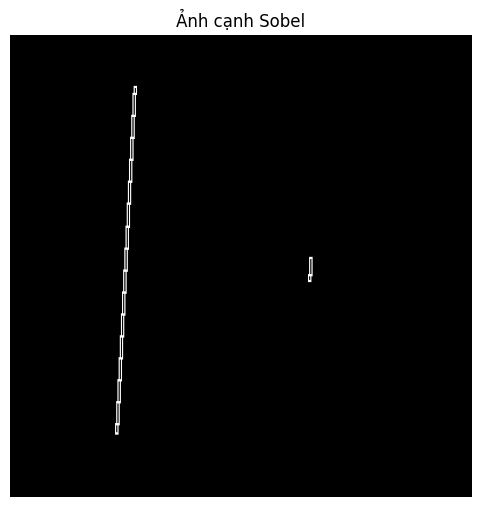

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import time

# Kiểm tra các phần cần chạy trước
if "test_image" not in globals():
    raise RuntimeError("Hãy chạy cell đọc ảnh trước.")

if not callable(globals().get("convolve2d")):
    raise RuntimeError("Hãy chạy cell định nghĩa convolve2d trước.")

# Thông tin đường chuẩn trong ảnh thử của Gấm
ground_truth = [(110, 3, 300), (270, 3, 20)]
rho0, theta0_deg = 110, 3

# Kernel Sobel
sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = sobel_x.T


def sobel_edges(image, ratio=0.3):
    image = image.astype(np.float64)

    # Lật kernel vì convolve2d của nhóm thực hiện tích chập
    gx = convolve2d(
        image, np.flip(sobel_x), padding="reflect"
    )
    gy = convolve2d(
        image, np.flip(sobel_y), padding="reflect"
    )

    magnitude = np.hypot(gx, gy)
    edges = magnitude > ratio * magnitude.max()
    direction = np.arctan2(gy, gx)  # Radian, dùng cho Hough

    return edges, direction


# Tạo hai biến mà cell Hough đang cần
edge_map, gradient_direction = sobel_edges(test_image)

print("Kích thước ảnh cạnh:", edge_map.shape)
print("Kích thước hướng gradient:", gradient_direction.shape)
print("Số điểm cạnh:", int(edge_map.sum()))

plt.figure(figsize=(6, 6))
plt.imshow(edge_map, cmap="gray")
plt.title("Ảnh cạnh Sobel")
plt.axis("off")
plt.show()

## KT3 – Kiểm tra đỉnh đúng $(\rho_0, \theta_0)$

In [13]:

import numpy as np

# ============================================================
# KT3 - KIỂM TRA ĐỈNH ĐÚNG (rho0, theta0)
# Khôi phục dữ liệu để các cell phía sau dùng thống nhất
# ============================================================

rho0, theta0_deg = 110, 3

# Tính lại bản đồ cạnh và hướng gradient từ ảnh thử
edge_map, gradient_direction = sobel_edges(test_image)

# Tạo lại kết quả Hough, tránh phụ thuộc vào biến results cũ
results = {}

for name, grad in [
    ("thường", None),
    ("theo gradient", gradient_direction)
]:
    A, th, rh = hough_accumulate(
        edge_map,
        grad_dir=grad
    )

    A_smooth_mode = smooth_accumulator(A, smooth_sigma=1.0)

    peaks = find_peaks(
        A,
        n_peaks=5,
        nms_radius=3,
        smooth_sigma=1.0,
        thetas=th,
        rhos=rh
    )

    results[name] = (A, A_smooth_mode, peaks)

    if name == "thường":
        thetas, rhos = th, rh

    print(f"{name}: tìm được {len(peaks)} đỉnh")

# Giữ các biến tương thích với những cell cũ
A_plain = results["thường"][0]
A_grad = results["theo gradient"][0]
A_smooth = results["thường"][1]

print("\nCác chế độ:", list(results.keys()))


def angle_distance_deg(a, b):
    """Sai số góc modulo 180 độ."""
    d = abs(a - b) % 180
    return min(d, 180 - d)


def check_peak(peak, rho0, theta0_deg,
               rho_tol=2, theta_tol_deg=1):
    """Kiểm tra sai số của đỉnh Hough."""
    rho, theta, _ = peak
    theta_deg = np.rad2deg(theta)

    # Xử lý tính tương đương (rho, theta)
    if abs(theta_deg - theta0_deg) > 90:
        rho = -rho

    e_theta = angle_distance_deg(theta_deg, theta0_deg)
    e_rho = abs(rho - rho0)

    ok = e_rho <= rho_tol and e_theta <= theta_tol_deg

    return ok, e_rho, e_theta


print(f"\nĐáp án: rho0 = {rho0}, theta0 = {theta0_deg}°")
print("Dung sai nhóm tự đặt: 2 px, 1°\n")

for name, (_, _, peaks) in results.items():

    if len(peaks) == 0:
        print(f"Bỏ phiếu {name}: không tìm được đỉnh")
        continue

    ok, e_rho, e_theta = check_peak(
        peaks[0], rho0, theta0_deg
    )

    print(
        f"Bỏ phiếu {name:13s}: "
        f"đỉnh mạnh nhất = "
        f"({peaks[0][0]:.0f}, "
        f"{np.rad2deg(peaks[0][1]):.0f}°)"
        f" | sai số rho = {e_rho:.1f} px"
        f" | sai số góc = {e_theta:.1f}°"
        f" -> {'ĐẠT' if ok else 'KHÔNG ĐẠT'}"
    )

# Kiểm tra đoạn ngắn tại đáp án (270, 3°)
i270 = np.argmin(np.abs(rhos - 270))
j3 = np.argmin(np.abs(np.rad2deg(thetas) - 3))

short_score = A_smooth[i270, j3]
plain_peaks = results["thường"][2]

print(
    f"\nĐoạn ngắn (270, 3°): "
    f"điểm tích lũy tại ô đáp án = {short_score:.1f}"
)

if len(plain_peaks) >= 2:
    print(
        f"Điểm tích lũy đỉnh mạnh thứ hai = "
        f"{plain_peaks[1][2]:.1f}"
    )

print("\nHoàn thành kiểm tra đỉnh Hough.")


thường: tìm được 5 đỉnh
theo gradient: tìm được 5 đỉnh

Các chế độ: ['thường', 'theo gradient']

Đáp án: rho0 = 110, theta0 = 3°
Dung sai nhóm tự đặt: 2 px, 1°

Bỏ phiếu thường       : đỉnh mạnh nhất = (110, 3°) | sai số rho = 0.0 px | sai số góc = 0.0° -> ĐẠT
Bỏ phiếu theo gradient: đỉnh mạnh nhất = (110, 3°) | sai số rho = 0.0 px | sai số góc = 0.0° -> ĐẠT

Đoạn ngắn (270, 3°): điểm tích lũy tại ô đáp án = 13.2
Điểm tích lũy đỉnh mạnh thứ hai = 113.4

Hoàn thành kiểm tra đỉnh Hough.


Tâm đoạn ngắn: (259.8, 202.5), độ phân giải góc ≈ 2.9°

Bỏ phiếu thường:
  smooth_sigma = 0: (269, 3°) | sai số rho = 1 px, sai số góc = 0° | cách tâm đoạn 1.0 px | 3 ô có điểm ≥ 90% đỉnh
  smooth_sigma = 1.0: (270, 3°) | sai số rho = 0 px, sai số góc = 0° | cách tâm đoạn 0.0 px | 21 ô có điểm ≥ 90% đỉnh

Bỏ phiếu theo gradient:
  smooth_sigma = 0: (269, 3°) | sai số rho = 1 px, sai số góc = 0° | cách tâm đoạn 1.0 px | 2 ô có điểm ≥ 90% đỉnh
  smooth_sigma = 1.0: (273, 4°) | sai số rho = 3 px, sai số góc = 1° | cách tâm đoạn 0.2 px | 15 ô có điểm ≥ 90% đỉnh



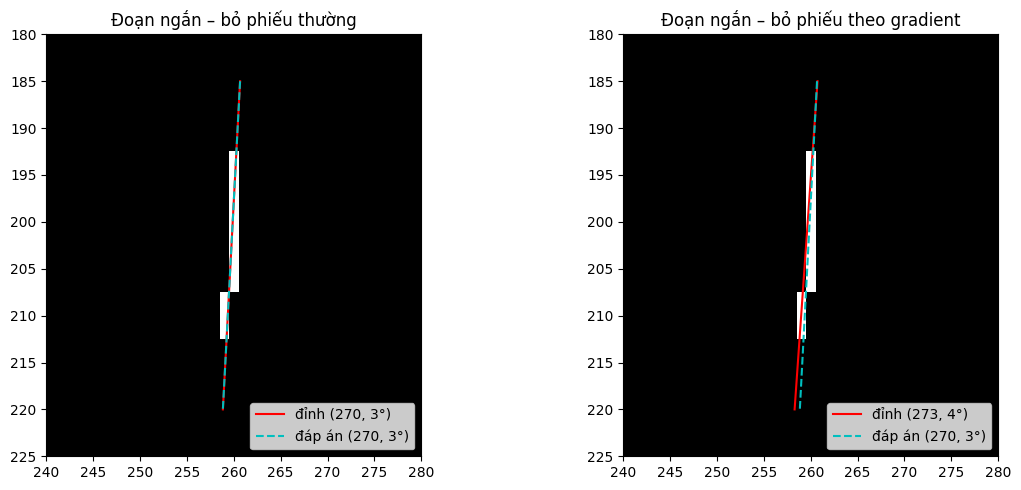

In [15]:
short_image = test_image.copy()
short_image[:, :250] = 0
short_edges, short_grad = sobel_edges(short_image)

ys_s, xs_s = np.nonzero(short_image > 127)
center_x, center_y = xs_s.mean(), ys_s.mean()
length = 20
resolution_deg = np.rad2deg(1 / length)
print(f"Tâm đoạn ngắn: ({center_x:.1f}, {center_y:.1f}), độ phân giải góc ≈ {resolution_deg:.1f}°\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, g) in zip(axes, [("thường", None), ("theo gradient", short_grad)]):
    A, thetas_s, rhos_s = hough_accumulate(short_edges, grad_dir=g)
    print(f"Bỏ phiếu {name}:")
    for sigma in [0, 1.0]:
        peaks = find_peaks(A, 1, smooth_sigma=sigma, thetas=thetas_s, rhos=rhos_s)
        A_used = smooth_accumulator(A, sigma)
        rho, theta, score = peaks[0]
        dist = abs(center_x * np.cos(theta) + center_y * np.sin(theta) - rho)
        e_theta = angle_distance_deg(np.rad2deg(theta), 3)
        _, e_rho, _ = check_peak(peaks[0], 270, 3)
        n_best = int(np.sum(A_used >= 0.9 * score))
        print(f"  smooth_sigma = {sigma}: ({rho:.0f}, {np.rad2deg(theta):.0f}°)"
              f" | sai số rho = {e_rho:.0f} px, sai số góc = {e_theta:.0f}°"
              f" | cách tâm đoạn {dist:.1f} px | {n_best} ô có điểm ≥ 90% đỉnh")
        if sigma > 0:
            ys_line = np.arange(185, 221)
            ax.plot((rho - ys_line * np.sin(theta)) / np.cos(theta), ys_line, "r-", label=f"đỉnh ({rho:.0f}, {np.rad2deg(theta):.0f}°)")
    ax.imshow(short_image, cmap="gray", vmin=0, vmax=255)
    ys_true = np.arange(185, 221)
    t3 = np.deg2rad(3)
    ax.plot((270 - ys_true * np.sin(t3)) / np.cos(t3), ys_true, "c--", label="đáp án (270, 3°)")
    ax.set_xlim(240, 280)
    ax.set_ylim(225, 180)
    ax.set_title(f"Đoạn ngắn – bỏ phiếu {name}")
    ax.legend(loc="lower right")
    print()
plt.tight_layout()
plt.show()

### So sánh hai cách làm mờ: chỉ theo $\rho$ (nhóm chọn) và Gauss 2 chiều
Cùng σ = 1 ô. Bản 2 chiều chỉ viết trong ô này để so sánh, không phải hàm nộp; nó nối cột θ quấn vòng (lật ρ) trước khi tích chập. Báo đỉnh mạnh nhất cùng sai số $\rho$ và sai số góc so với đáp án.

In [16]:
def smooth_2d(A, sigma=1.0):
    r = int(np.ceil(3 * sigma))
    x = np.arange(-r, r + 1)
    k = np.exp(-x**2 / (2 * sigma**2))
    k /= k.sum()
    extended = np.hstack([A[::-1, -r:], A, A[::-1, :r]])
    return convolve2d(extended, np.outer(k, k), padding="constant")[:, r:-r]


print(f"{'ảnh':10s} {'bỏ phiếu':14s} | {'chỉ theo rho':28s} | {'Gauss 2 chiều':28s}")
for label, edges_c, grad_c, (r_true, t_true) in [
        ("đoạn dài", edge_map, gradient_direction, (rho0, theta0_deg)),
        ("đoạn ngắn", short_edges, short_grad, (270, 3))]:
    for name, g in [("thường", None), ("theo gradient", grad_c)]:
        A, th, rh = hough_accumulate(edges_c, grad_dir=g)
        row = []
        for S_c in [smooth_accumulator(A, 1.0), smooth_2d(A, 1.0)]:
            i, j = np.unravel_index(np.argmax(S_c), S_c.shape)
            peak = (rh[i], th[j], S_c[i, j])
            _, e_rho, e_theta = check_peak(peak, r_true, t_true)
            row.append(f"({rh[i]:.0f}, {np.rad2deg(th[j]):.0f}°) lệch {e_rho:.0f} px, {e_theta:.0f}°")
        print(f"{label:10s} {name:14s} | {row[0]:28s} | {row[1]:28s}")

ảnh        bỏ phiếu       | chỉ theo rho                 | Gauss 2 chiều               
đoạn dài   thường         | (110, 3°) lệch 0 px, 0°      | (110, 3°) lệch 0 px, 0°     
đoạn dài   theo gradient  | (110, 3°) lệch 0 px, 0°      | (110, 3°) lệch 0 px, 0°     
đoạn ngắn  thường         | (270, 3°) lệch 0 px, 0°      | (308, 17°) lệch 38 px, 14°  
đoạn ngắn  theo gradient  | (273, 4°) lệch 3 px, 1°      | (296, 12°) lệch 26 px, 9°   


### Kiểm tra thêm: lưới góc và tham số `theta_range`, `rho_range`, `n_theta`, `n_rho`
Lưới $\theta$ được tạo từ `n_theta` (không còn tham số bước góc), nên luôn phủ đủ `theta_range`: góc cuối + bước = đầu mút trên. Ví dụ `n_theta = 22` cho bước ≈ 8.18° và không bỏ sót góc nào ở cuối như trường hợp bước 8° trước đây (chỉ tới 168°, mất 176°).

In [17]:
for label, kwargs in [("mặc định", dict()),
                      ("n_theta=22", dict(n_theta=22)),
                      ("n_theta=45", dict(n_theta=45)),
                      ("theta_range=(0, π/2), n_theta=90", dict(theta_range=(0, np.pi / 2), n_theta=90))]:
    A, th, rh = hough_accumulate(edge_map, **kwargs)
    step = np.rad2deg(th[1] - th[0])
    print(f"{label:34s}: {len(th):3d} góc, {np.rad2deg(th[0]):.1f}° → {np.rad2deg(th[-1]):6.2f}°,"
          f" bước {step:.2f}°, góc cuối + bước = {np.rad2deg(th[-1]) + step:.0f}°")

# Thu hẹp vùng tìm quanh đáp án: theta trong [0°, 10°) bước 0.5°, rho trong [100, 120] bước 1 px
A, th, rh = hough_accumulate(edge_map, theta_range=(0, np.deg2rad(10)), n_theta=20,
                             rho_range=(100, 120), n_rho=21)
rho_p, theta_p, votes_p = find_peaks(A, 1, thetas=th, rhos=rh)[0]
print(f"\nVùng hẹp, A có kích thước {A.shape}: đỉnh ({rho_p:.1f}, {np.rad2deg(theta_p):.1f}°), điểm tích lũy = {votes_p:.1f}")
print("Lưu ý: smooth_sigma tính bằng số ô rho, nên nếu đổi bước rho thì chỉnh smooth_sigma theo"
      " (hai mép đường cách nhau khoảng 2 px).")

mặc định                          : 180 góc, 0.0° → 179.00°, bước 1.00°, góc cuối + bước = 180°
n_theta=22                        :  22 góc, 0.0° → 171.82°, bước 8.18°, góc cuối + bước = 180°
n_theta=45                        :  45 góc, 0.0° → 176.00°, bước 4.00°, góc cuối + bước = 180°
theta_range=(0, π/2), n_theta=90  :  90 góc, 0.0° →  89.00°, bước 1.00°, góc cuối + bước = 90°

Vùng hẹp, A có kích thước (21, 20): đỉnh (110.0, 3.0°), điểm tích lũy = 162.6
Lưu ý: smooth_sigma tính bằng số ô rho, nên nếu đổi bước rho thì chỉnh smooth_sigma theo (hai mép đường cách nhau khoảng 2 px).


## KT3 – Ô đối chiếu thư viện (chỉ ở đây mới được gọi hàm bị cấm)

In [18]:
lines = cv2.HoughLines(edge_map.astype(np.uint8) * 255, 1, np.pi / 180, 50)

print("cv2.HoughLines (bước 1 px, 1°), 3 đường đầu:")
for rho, theta in lines[:3, 0]:
    print(f"  rho = {rho:6.1f}, theta = {np.rad2deg(theta):5.1f}°")

rho_mine, theta_mine, _ = results["thường"][2][0]
print(f"\nHàm tự viết, đỉnh mạnh nhất: rho = {rho_mine:6.1f}, theta = {np.rad2deg(theta_mine):5.1f}°")

cv2.HoughLines (bước 1 px, 1°), 3 đường đầu:
  rho =  109.0, theta =   3.0°
  rho =  111.0, theta =   3.0°
  rho =  106.0, theta =   2.0°

Hàm tự viết, đỉnh mạnh nhất: rho =  110.0, theta =   3.0°


# VÒNG 3 – Tấn Lên: Thí nghiệm KT3 (b)

**Nhiệm vụ:** so sánh Hough thô / mịn / đa tỉ lệ theo sai số góc, độ rõ đỉnh và thời gian; bật/tắt bỏ phiếu theo gradient; lập bảng và nhận xét.

**Nguồn kế thừa:** `main` tại commit `74a07c2fe7021b60c11a957f53705d7e57c93ede`:
- `len.ipynb`: `convolve2d`, `sobel_edges`, `hough_accumulate`, `smooth_accumulator`, `find_peaks`.
- `hiep.ipynb`: `hough_multiscale` (chỉ nạp để tham khảo; bảng so sánh dùng quy trình chung `v3_detect` để cả ba phương pháp dùng cùng `hough_accumulate`, làm mượt và NMS).
- `gam.ipynb`: `angle_error`, `rho_error` và các ảnh thử trong `images/`.
 

**Thiết kế so sánh**

| Phương pháp | Bước góc | Bước rho | Phạm vi |
|---|---:|---:|---|
| Thô | 1° | 2 px | Toàn miền |
| Mịn | 0.125° | 0.25 px | Toàn miền |
| Đa tỉ lệ | 1° → 0.125° | 2 → 0.25 px | Thô toàn miền, một lần tinh chỉnh quanh mỗi đỉnh |

`n_levels=1` nghĩa là **một lần tinh chỉnh sau lưới thô**, không phải chỉ có một lưới. Dùng hệ số 8 để lưới cuối của đa tỉ lệ có cùng độ phân giải với Hough mịn. Cả ba lấy tối đa 10 đỉnh; `find_peaks` dùng mặc định sigma=1 ô rho, NMS=3 ô theo code nhóm. Do đó bề rộng làm mượt và NMS theo đơn vị vật lý không giống nhau giữa lưới thô/mịn. Đây là so sánh các cấu hình hiện có, không tách riêng ảnh hưởng của từng tham số.

Tất cả dùng **cùng ảnh cạnh Sobel** (`ratio=0.3`). Gradient là hướng Sobel tính từ ảnh, không dùng góc đáp án để bỏ phiếu. Bật gradient với `delta_deg=10`; tắt bằng `None`. Thời gian chỉ tính gọi bộ phát hiện (bỏ phiếu, làm mượt, tìm đỉnh và tinh chỉnh), không gồm đọc ảnh, Sobel, đánh giá hay vẽ. Báo trung vị 3 lượt và khoảng min–max; đổi thứ tự chạy giữa các lượt. Bản Python dùng vòng lặp tích chập nên toàn bộ notebook có thể cần nhiều phút.

**Ba chỉ số chính**
1. Sai số góc: $e_\theta=\min(|\theta-\theta_0|\bmod180,180-(|\theta-\theta_0|\bmod180))$, đơn vị độ.
2. Độ rõ đỉnh: **PSR tại nghiệm trên lưới đánh giá chung**: $(P-\mu_B)/\sigma_B$. Lập bảng phiếu cục bộ quanh đường trả về bằng *toàn bộ* điểm cạnh của ảnh và cùng chế độ gradient; bước 0.25 px / 0.125°, vùng ±6 px / ±3°, làm mượt sigma=1 ô rho. $P$ là điểm tại đúng nghiệm, không lấy lại cực đại. Nền $B$ loại hình chữ nhật ±1 px / ±0.5° quanh nghiệm. Chỉ số lớn nghĩa là điểm tại nghiệm nổi bật hơn nền cục bộ; có thể thấp hoặc âm nếu nghiệm không trùng đỉnh của lưới đánh giá. **Không so trực tiếp số phiếu đỉnh giữa bảng thô và bảng tinh chỉnh dùng tập điểm khác nhau.** PSR này là quy ước bổ sung để so sánh công bằng, không phải độ cao đỉnh nội bộ của hàm đa tỉ lệ.
3. Thời gian (ms): trung vị và min–max qua 3 lượt, phụ thuộc máy chạy.

**Ghép đường để đánh giá:** ghép một–một các đỉnh trả về với đường chuẩn, trong cửa sổ sai số rho ≤6 px và góc ≤10°. Trong cửa sổ, ưu tiên đỉnh xuất hiện trước trong danh sách bộ phát hiện; nếu một đỉnh cùng phù hợp nhiều đường chuẩn, ưu tiên tổng sai số chuẩn hóa nhỏ hơn. Không dùng đáp án để chọn đỉnh có góc đẹp nhất trong top-10. Đây là dung sai *ghép*, không phải tiêu chí kết luận chính xác. Không tìm được ứng viên thì ghi `KHÔNG TÌM THẤY` và NaN, không tính thành sai số 0. Đoạn ngắn được báo riêng để tránh chỉ đánh giá đoạn dài. Các ảnh chuẩn là nét raster 1 px; Sobel tạo hai mép nên rho có thể lệch đường tâm.

In [19]:
import ast
import json
from pathlib import Path

v3_root = Path.cwd()
if v3_root.name == 'lam_viec':
    v3_root = v3_root.parent
if not (v3_root / 'lam_viec').is_dir():
    raise FileNotFoundError('Chạy từ thư mục gốc repo hoặc lam_viec/.')

for v3_name in ['convolve2d', 'sobel_edges', 'hough_accumulate',
                'smooth_accumulator', 'find_peaks']:
    if not callable(globals().get(v3_name)):
        raise RuntimeError(f'Hãy chạy phần vòng 1–2 trước: thiếu {v3_name}.')

def v3_load_functions(filename, names, namespace):
    document = json.loads(filename.read_text(encoding='utf-8'))
    loaded = set()
    for c in document['cells']:
        if c['cell_type'] != 'code':
            continue
        for node in ast.parse(''.join(c['source'])).body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                exec(compile(ast.Module(body=[node], type_ignores=[]),
                             str(filename), 'exec'), namespace)
                loaded.add(node.name)
    if loaded != set(names):
        raise RuntimeError(f'{filename.name}: thiếu {set(names) - loaded}')

# Namespace riêng: không ghi đè hàm/biến của các vòng trước.
v3_shared = dict(np=np, hough_accumulate=hough_accumulate, find_peaks=find_peaks)
v3_load_functions(v3_root / 'lam_viec/hiep.ipynb', {'hough_multiscale'}, v3_shared)
v3_load_functions(v3_root / 'lam_viec/gam.ipynb', {'angle_error', 'rho_error'}, v3_shared)
v3_original_multiscale = v3_shared['hough_multiscale']
v3_angle_error = v3_shared['angle_error']
v3_rho_error = v3_shared['rho_error']
print('Đã nạp hàm gốc của Hiệp để tham khảo và hai hàm đo sai số của Gấm. Bảng so sánh dùng quy trình chung ở ô v3_detect bên dưới.')

Đã nạp hàm gốc của Hiệp để tham khảo và hai hàm đo sai số của Gấm. Bảng so sánh dùng quy trình chung ở ô v3_detect bên dưới.


OK: Gần 0° | Ảnh: hough_angle_0_5.png | Kích thước: (400, 400) | Điểm cạnh: 620
Đáp án chuẩn: [('Dài', 200, 0.5, 300)]
-------------------------------------------------------
OK: Gần 180° | Ảnh: hough_angle_179_5.png | Kích thước: (400, 400) | Điểm cạnh: 620
Đáp án chuẩn: [('Dài', -200, 179.5, 300)]
-------------------------------------------------------
OK: Dài + ngắn | Ảnh: hough_test.png | Kích thước: (400, 400) | Điểm cạnh: 724
Đáp án chuẩn: [('Dài', 110, 3, 300), ('Ngắn', 270, 3, 20)]
-------------------------------------------------------


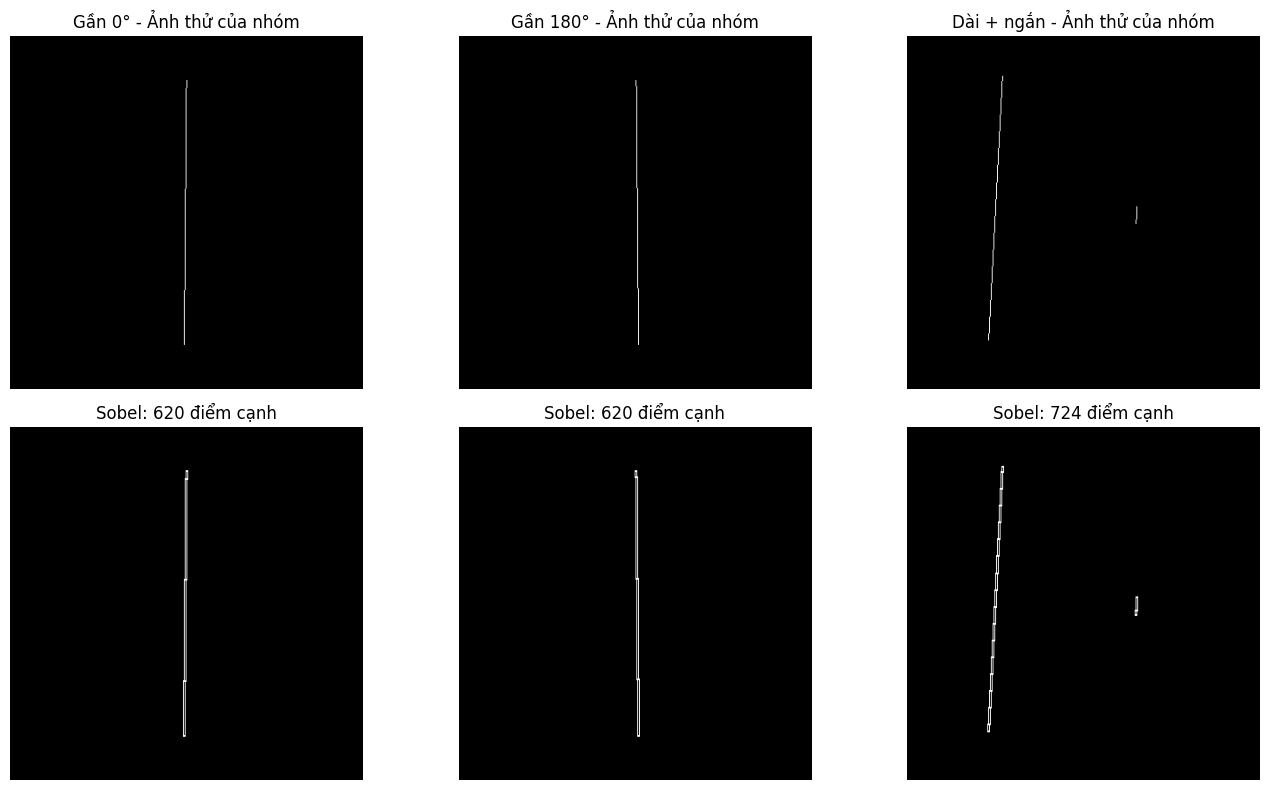


KIỂM TRA HOÀN THÀNH CELL V3.1
Số trường hợp thí nghiệm: 3
Các phương pháp: ['Thô', 'Mịn', 'Đa tỉ lệ']
Bỏ phiếu theo gradient: ['Tắt', 'Bật']

THÀNH CÔNG - Sẵn sàng chạy cell V3.2!


In [21]:

# ============================================================
# VÒNG 3 - CELL V3.1: NẠP ĐÚNG HÀM VÀ DỮ LIỆU CỦA NHÓM
# FIX LỖI ĐỌC ẢNH ĐƯỜNG DẪN TIẾNG VIỆT
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

# 1. Cấu hình thí nghiệm vòng 3
V3_REPEATS = 3
V3_N_PEAKS = 10
V3_DELTA_DEG = 10.0
V3_REFINE = 8
V3_COARSE_DR = 2.0
V3_COARSE_DT = 1.0
V3_SMOOTH_RHO = 0.5
V3_NMS_RHO = 6.0
V3_NMS_THETA = 3.0

V3_METHODS = ['Thô', 'Mịn', 'Đa tỉ lệ']
V3_MODES = ['Tắt', 'Bật']

# 2. Danh sách ảnh và đáp án chuẩn
v3_specs = [
    (
        'Gần 0°',
        'hough_angle_0_5.png',
        [('Dài', 200, 0.5, 300)]
    ),
    (
        'Gần 180°',
        'hough_angle_179_5.png',
        [('Dài', -200, 179.5, 300)]
    ),
    (
        'Dài + ngắn',
        'hough_test.png',
        [
            ('Dài', 110, 3, 300),
            ('Ngắn', 270, 3, 20)
        ]
    )
]

# 3. Hàm đọc ảnh hỗ trợ Unicode trên Windows
def v3_read_image(path):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy file ảnh: {path}"
        )

    data = np.fromfile(str(path), dtype=np.uint8)

    if data.size == 0:
        raise ValueError(f"File ảnh rỗng: {path}")

    image = cv2.imdecode(
        data,
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise ValueError(
            f"Không giải mã được ảnh: {path}"
        )

    return image


# 4. Nạp ảnh, tính Sobel và tạo dữ liệu thí nghiệm
v3_cases = []

fig, axes = plt.subplots(
    2, 3,
    figsize=(14, 8)
)

for col, (name, filename, truth) in enumerate(v3_specs):

    image_path = v3_root / 'images' / filename

    # FIX: Không sử dụng cv2.imread với đường dẫn Unicode
    image = v3_read_image(image_path)

    # Sử dụng hàm Sobel tự viết của nhóm
    edges, grad = sobel_edges(
        image,
        ratio=0.3
    )

    # Kiểm tra dữ liệu
    assert edges.shape == image.shape, \
        "Kích thước edge map không khớp ảnh"

    assert grad.shape == image.shape, \
        "Kích thước gradient không khớp ảnh"

    assert np.isfinite(grad[edges]).all(), \
        "Gradient chứa giá trị không hợp lệ"

    # Giữ nguyên cấu trúc dữ liệu cho các cell phía sau
    v3_cases.append(
        dict(
            name=name,
            image=image,
            edges=edges,
            grad=grad,
            truth=truth
        )
    )

    # Hiển thị ảnh gốc
    axes[0, col].imshow(
        image,
        cmap='gray',
        vmin=0,
        vmax=255
    )
    axes[0, col].set_title(
        f'{name} - Ảnh thử của nhóm'
    )

    # Hiển thị biên Sobel
    axes[1, col].imshow(
        edges,
        cmap='gray'
    )
    axes[1, col].set_title(
        f'Sobel: {int(edges.sum())} điểm cạnh'
    )

    print(
        f"OK: {name} | "
        f"Ảnh: {filename} | "
        f"Kích thước: {image.shape} | "
        f"Điểm cạnh: {int(edges.sum())}"
    )
    print(f"Đáp án chuẩn: {truth}")
    print("-" * 55)

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.show()

# 5. Kiểm tra dữ liệu đầu ra
print("\n" + "=" * 55)
print("KIỂM TRA HOÀN THÀNH CELL V3.1")
print("=" * 55)

print("Số trường hợp thí nghiệm:", len(v3_cases))
print("Các phương pháp:", V3_METHODS)
print("Bỏ phiếu theo gradient:", V3_MODES)

assert len(v3_cases) == 3, \
    "Số lượng trường hợp thí nghiệm không đúng"

print("\nTHÀNH CÔNG - Sẵn sàng chạy cell V3.2!")


In [22]:
def v3_stage(edges, grad, theta_range, rho_range, n_theta, n_rho,
             n_peaks, nms_rho, nms_theta, crop_rho=0):
    A, th, rh = hough_accumulate(
        edges, theta_range=theta_range, rho_range=rho_range,
        n_theta=n_theta, n_rho=n_rho,
        grad_dir=grad, delta_deg=V3_DELTA_DEG)
    dr = float(rh[1] - rh[0])
    dt = float(np.rad2deg(th[1] - th[0]))
    S = smooth_accumulator(A, smooth_sigma=V3_SMOOTH_RHO / dr)
    if crop_rho:
        S, rh = S[crop_rho:-crop_rho], rh[crop_rho:-crop_rho]
    radii = (int(np.ceil(nms_rho / dr)), int(np.ceil(nms_theta / dt)))
    return find_peaks(S, n_peaks, nms_radius=radii, smooth_sigma=0,
                      thetas=th, rhos=rh)


def v3_detect(edges, grad, method, n_peaks=None, nms_rho=None, nms_theta=None):
    if method not in V3_METHODS:
        raise ValueError(method)
    n_peaks = V3_N_PEAKS if n_peaks is None else n_peaks
    nms_rho = V3_NMS_RHO if nms_rho is None else nms_rho
    nms_theta = V3_NMS_THETA if nms_theta is None else nms_theta
    h, w = edges.shape
    D = np.ceil(np.hypot(h, w) / V3_COARSE_DR) * V3_COARSE_DR
    factor = V3_REFINE if method == 'Mịn' else 1
    dr, dt = V3_COARSE_DR / factor, V3_COARSE_DT / factor
    peaks = v3_stage(
        edges, grad, (0, np.pi), (-D, D),
        int(np.ceil(180 / dt)), int(round(2 * D / dr)) + 1,
        n_peaks, nms_rho, nms_theta)
    if method != 'Đa tỉ lệ':
        return [(float(r), float(t)) for r, t, _ in peaks]

    # Theo mục 4.3: chỉ các điểm đã bỏ phiếu cho ô thô được tinh chỉnh.
    fine_dr = V3_COARSE_DR / V3_REFINE
    fine_dt = np.deg2rad(V3_COARSE_DT / V3_REFINE)
    coarse_dt = np.deg2rad(V3_COARSE_DT)
    pad = int(np.ceil(3 * V3_SMOOTH_RHO / fine_dr))
    refined = []
    ys, xs = np.nonzero(edges)
    for rho, theta, _ in peaks:
        bins = np.rint((xs * np.cos(theta) + ys * np.sin(theta) + D)
                       / V3_COARSE_DR).astype(int)
        chosen = bins == int(round((rho + D) / V3_COARSE_DR))
        if grad is not None:
            directions = np.asarray(grad)[ys, xs]
            difference = np.abs((directions - theta + np.pi / 2) % np.pi - np.pi / 2)
            chosen &= difference <= np.deg2rad(V3_DELTA_DEG)
        if not chosen.any():
            continue
        local_edges = np.zeros_like(edges, dtype=bool)
        local_edges[ys[chosen], xs[chosen]] = True
        local = v3_stage(
            local_edges, grad,
            (theta - coarse_dt, theta + coarse_dt + fine_dt),
            (rho - V3_COARSE_DR - pad * fine_dr,
             rho + V3_COARSE_DR + pad * fine_dr),
            2 * V3_REFINE + 1, 2 * V3_REFINE + 1 + 2 * pad,
            1, nms_rho, nms_theta, crop_rho=pad)
        if not local:
            continue
        r, t, score = local[0]
        if int(np.floor(t / np.pi)) % 2:
            r = -r
        t = float(t % np.pi)
        if t >= np.pi:  # Sai số làm tròn có thể đưa góc âm rất nhỏ thành đúng pi.
            t, r = 0.0, -r
        refined.append((float(r), t, score))
    refined.sort(key=lambda peak: peak[2], reverse=True)
    return [(r, t) for r, t, _ in refined]

print('Cả ba cách dùng hough_accumulate, smooth_accumulator, find_peaks của nhóm.')
print(f'Làm mượt rho: sigma={V3_SMOOTH_RHO} px; NMS: {V3_NMS_RHO} px / {V3_NMS_THETA} độ.')
print('Lưới cuối mịn/đa tỉ lệ: 0.125 độ, 0.25 px; đa tỉ lệ tinh chỉnh 1 lần.')


Cả ba cách dùng hough_accumulate, smooth_accumulator, find_peaks của nhóm.
Làm mượt rho: sigma=0.5 px; NMS: 6.0 px / 3.0 độ.
Lưới cuối mịn/đa tỉ lệ: 0.125 độ, 0.25 px; đa tỉ lệ tinh chỉnh 1 lần.


In [23]:
def v3_match(peaks, truth, rho_tol=6.0, theta_tol=10.0):
    candidates = []
    for ti, (_, r0, t0, _) in enumerate(truth):
        for pi, (r, t) in enumerate(peaks):
            td = float(np.rad2deg(t))
            er = v3_rho_error(r0, t0, r, td)
            et = v3_angle_error(t0, td)
            if er <= rho_tol and et <= theta_tol:
                candidates.append((pi, er / rho_tol + et / theta_tol, ti))
    matched, used = {}, set()
    for pi, _, ti in sorted(candidates):
        if ti not in matched and pi not in used:
            matched[ti] = pi
            used.add(pi)
    return matched

def v3_peak_metrics(edges, grad, rho, theta):
    dr, dt = 0.25, np.deg2rad(0.125)
    # ±6 px, ±3°; thêm 3 ô rho để đủ biên kernel sigma=1.
    nr, nt = 24, 24
    pad = int(np.ceil(3 * V3_SMOOTH_RHO / dr))
    A, th, rh = hough_accumulate(
        edges, theta_range=(theta - nt * dt, theta + (nt + 1) * dt),
        rho_range=(rho - (nr + pad) * dr, rho + (nr + pad) * dr),
        n_theta=2 * nt + 1, n_rho=2 * (nr + pad) + 1,
        grad_dir=grad, delta_deg=V3_DELTA_DEG)
    S = smooth_accumulator(A, smooth_sigma=V3_SMOOTH_RHO / dr)[pad:-pad]
    offsets_r = np.arange(-nr, nr + 1) * dr
    offsets_t = np.arange(-nt, nt + 1) * 0.125
    main_lobe = ((np.abs(offsets_r[:, None]) <= 1.0)
                 & (np.abs(offsets_t[None, :]) <= 0.5))
    background = S[~main_lobe]
    peak = float(S[nr, nt])
    mean, std = float(background.mean()), float(background.std())
    ratio = peak / mean if mean > 1e-12 else np.nan
    psr = (peak - mean) / std if std > 1e-12 else np.nan
    return dict(peak=peak, background=mean, peak_ratio=ratio, psr=psr)

# Kiểm tra quy ước góc và dấu rho trước khi đo.
assert np.isclose(v3_angle_error(0.5, 179.5), 1.0)
assert np.isclose(v3_rho_error(200, 0.5, -200, 180.5), 0.0)
assert v3_match([], v3_cases[0]['truth']) == {}
print('Quy ước quấn vòng góc và trường hợp không có đỉnh: OK.')

Quy ước quấn vòng góc và trường hợp không có đỉnh: OK.


In [24]:
if V3_REPEATS < 3:
    raise ValueError('Dùng ít nhất 3 lượt cho bảng so sánh chính.')

v3_warm_edges = np.zeros((32, 32), dtype=bool)
v3_warm_edges[4:28, 16] = True
for v3_method in V3_METHODS:
    v3_detect(v3_warm_edges, None, v3_method)

v3_runs = {}
for case in v3_cases:
    for mode in V3_MODES:
        grad = case['grad'] if mode == 'Bật' else None
        for method in V3_METHODS:
            v3_runs[(case['name'], mode, method)] = dict(times=[], peaks=None)
        for repeat in range(V3_REPEATS):
            order = V3_METHODS[repeat % 3:] + V3_METHODS[:repeat % 3]
            for method in order:
                started = time.perf_counter()
                peaks = v3_detect(case['edges'], grad, method)
                elapsed_ms = (time.perf_counter() - started) * 1000
                item = v3_runs[(case['name'], mode, method)]
                item['times'].append(elapsed_ms)
                if item['peaks'] is not None:
                    assert np.allclose(np.asarray(peaks), np.asarray(item['peaks']))
                item['peaks'] = peaks
            print(f"{case['name']} | gradient {mode} | lượt {repeat + 1}/{V3_REPEATS}",
                  flush=True)
print('Đã đo xong 18 cấu hình, mỗi cấu hình 3 lượt.')

Gần 0° | gradient Tắt | lượt 1/3
Gần 0° | gradient Tắt | lượt 2/3
Gần 0° | gradient Tắt | lượt 3/3
Gần 0° | gradient Bật | lượt 1/3
Gần 0° | gradient Bật | lượt 2/3
Gần 0° | gradient Bật | lượt 3/3
Gần 180° | gradient Tắt | lượt 1/3
Gần 180° | gradient Tắt | lượt 2/3
Gần 180° | gradient Tắt | lượt 3/3
Gần 180° | gradient Bật | lượt 1/3
Gần 180° | gradient Bật | lượt 2/3
Gần 180° | gradient Bật | lượt 3/3
Dài + ngắn | gradient Tắt | lượt 1/3
Dài + ngắn | gradient Tắt | lượt 2/3
Dài + ngắn | gradient Tắt | lượt 3/3
Dài + ngắn | gradient Bật | lượt 1/3
Dài + ngắn | gradient Bật | lượt 2/3
Dài + ngắn | gradient Bật | lượt 3/3
Đã đo xong 18 cấu hình, mỗi cấu hình 3 lượt.


### Bảng so sánh đủ ba chỉ số

Báo riêng từng đường chuẩn. Thời gian là của toàn ảnh nên hai hàng dài/ngắn cùng cấu hình có chung thời gian; không cộng hai hàng đó. PSR càng lớn càng nổi bật, sai số góc và thời gian càng nhỏ càng tốt.



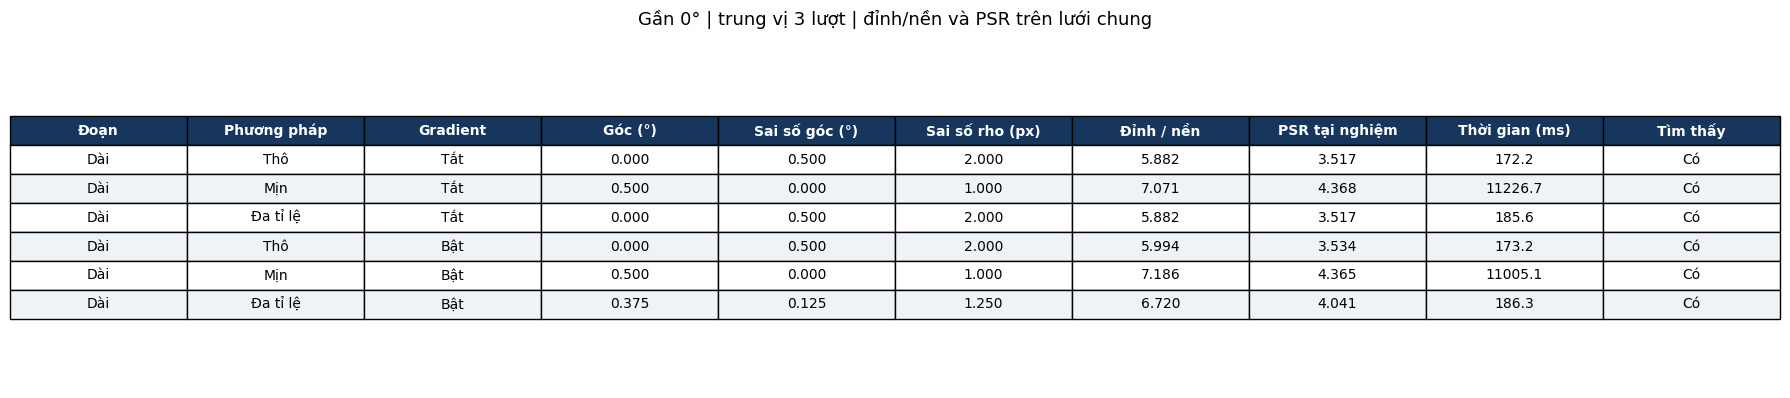

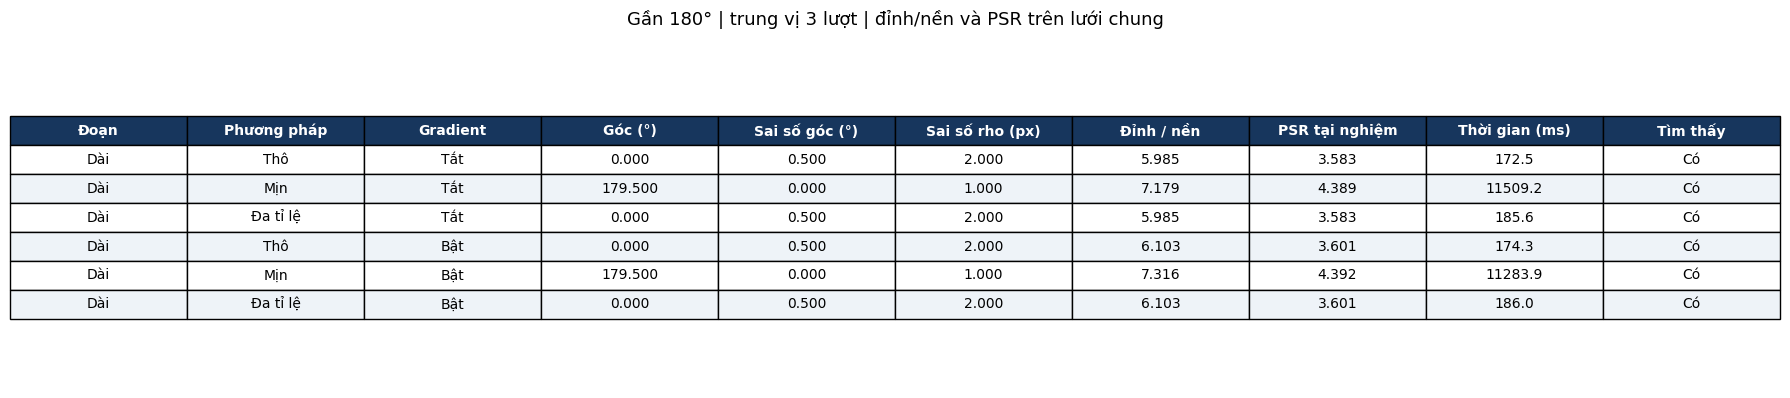

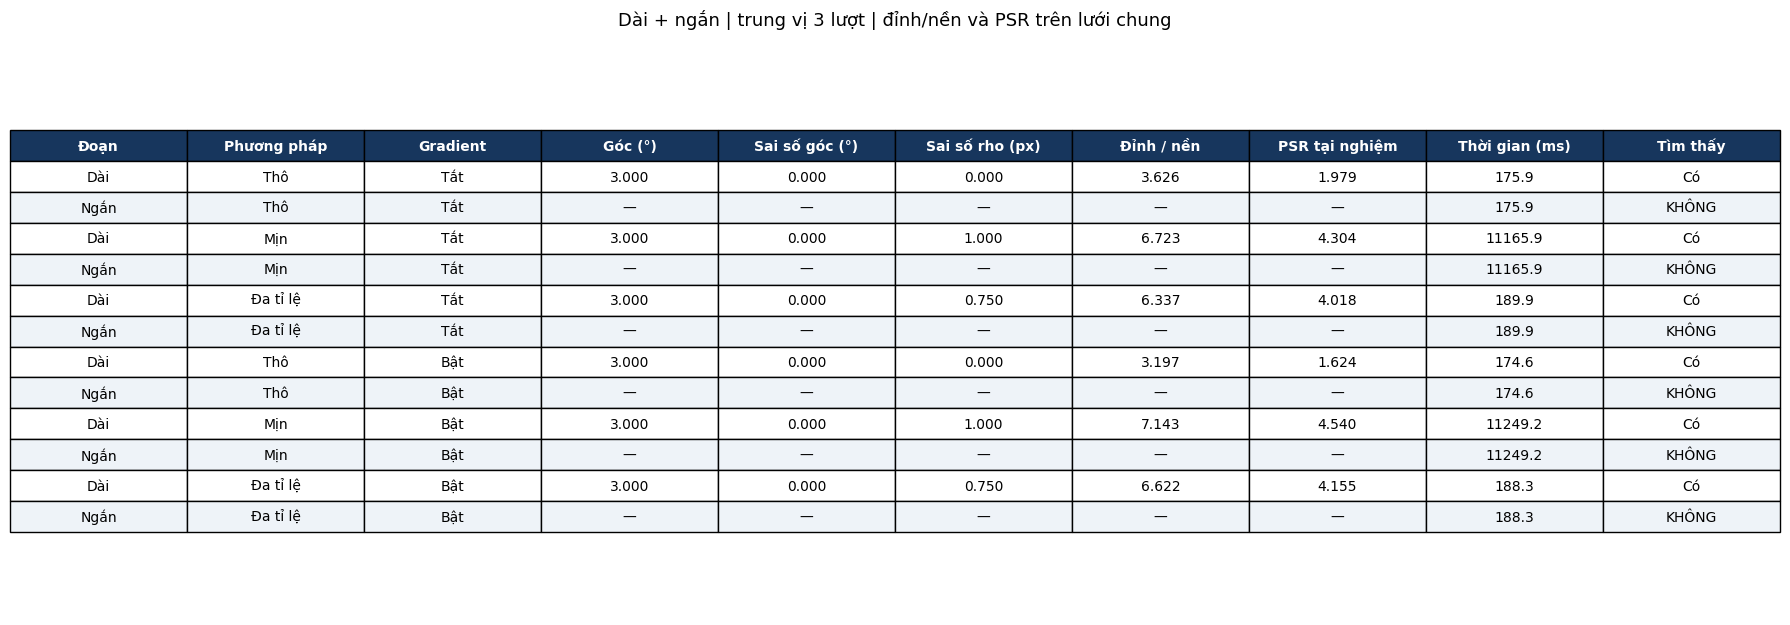

CHI TIẾT THỜI GIAN (ms): trung vị [min, max]
Gần 0°       | Tắt | Thô       |     172.2 [171.7, 173.7]
Gần 0°       | Tắt | Mịn       |   11226.7 [11129.1, 11275.2]
Gần 0°       | Tắt | Đa tỉ lệ  |     185.6 [184.1, 186.6]
Gần 0°       | Bật | Thô       |     173.2 [172.8, 175.5]
Gần 0°       | Bật | Mịn       |   11005.1 [10971.2, 11064.9]
Gần 0°       | Bật | Đa tỉ lệ  |     186.3 [186.3, 187.1]
Gần 180°     | Tắt | Thô       |     172.5 [172.3, 175.0]
Gần 180°     | Tắt | Mịn       |   11509.2 [11130.3, 11515.1]
Gần 180°     | Tắt | Đa tỉ lệ  |     185.6 [181.3, 187.9]
Gần 180°     | Bật | Thô       |     174.3 [173.5, 202.7]
Gần 180°     | Bật | Mịn       |   11283.9 [11155.8, 11321.6]
Gần 180°     | Bật | Đa tỉ lệ  |     186.0 [185.0, 188.0]
Dài + ngắn   | Tắt | Thô       |     175.9 [173.8, 177.3]
Dài + ngắn   | Tắt | Mịn       |   11165.9 [11133.1, 11337.1]
Dài + ngắn   | Tắt | Đa tỉ lệ  |     189.9 [188.6, 190.9]
Dài + ngắn   | Bật | Thô       |     174.6 [171.8, 176.6]
Dài + n

In [25]:
v3_records = []
for case in v3_cases:
    for mode in V3_MODES:
        grad = case['grad'] if mode == 'Bật' else None
        for method in V3_METHODS:
            run = v3_runs[(case['name'], mode, method)]
            matches = v3_match(run['peaks'], case['truth'])
            run['matches'] = matches
            for ti, (target, r0, t0, length) in enumerate(case['truth']):
                row = dict(image=case['name'], target=target, method=method,
                           gradient=mode, found=ti in matches,
                           theta=np.nan, angle_error=np.nan, rho_error=np.nan,
                           psr=np.nan, peak_ratio=np.nan, peak=np.nan, background=np.nan, time_ms=float(np.median(run['times'])))
                if ti in matches:
                    r, t = run['peaks'][matches[ti]]
                    row.update(theta=float(np.rad2deg(t)),
                               angle_error=v3_angle_error(t0, np.rad2deg(t)),
                               rho_error=v3_rho_error(r0, t0, r, np.rad2deg(t)))
                    row.update(v3_peak_metrics(case['edges'], grad, r, t))
                v3_records.append(row)

def v3_fmt(value, digits=3):
    return f'{value:.{digits}f}' if np.isfinite(value) else '—'

for case in v3_cases:
    rows = [r for r in v3_records if r['image'] == case['name']]
    values = [[r['target'], r['method'], r['gradient'], v3_fmt(r['theta']),
               v3_fmt(r['angle_error']), v3_fmt(r['rho_error']),
               v3_fmt(r['peak_ratio']), v3_fmt(r['psr']),
               v3_fmt(r['time_ms'], 1), 'Có' if r['found'] else 'KHÔNG'] for r in rows]
    fig, ax = plt.subplots(figsize=(18, 1.8 + 0.38 * len(rows)))
    ax.axis('off')
    table = ax.table(cellText=values,
        colLabels=['Đoạn', 'Phương pháp', 'Gradient', 'Góc (°)', 'Sai số góc (°)',
                   'Sai số rho (px)', 'Đỉnh / nền', 'PSR tại nghiệm', 'Thời gian (ms)', 'Tìm thấy'],
        loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1, 1.6)
    for (ri, ci), tc in table.get_celld().items():
        if ri == 0:
            tc.set_facecolor('#17365d')
            tc.set_text_props(color='white', weight='bold')
        elif ri % 2 == 0:
            tc.set_facecolor('#eef3f8')
    ax.set_title(case['name'] + ' | trung vị 3 lượt | đỉnh/nền và PSR trên lưới chung',
                 fontsize=13, pad=16)
    plt.tight_layout()
    plt.show()

print('CHI TIẾT THỜI GIAN (ms): trung vị [min, max]')
for (name, mode, method), run in v3_runs.items():
    t = run['times']
    print(f'{name:12s} | {mode:3s} | {method:9s} | '
          f'{np.median(t):9.1f} [{min(t):.1f}, {max(t):.1f}]')
print('\nSỐ LIỆU CHI TIẾT (để chép vào báo cáo):')
for row in v3_records:
    print(row)

### Biểu đồ sai số, PSR và thời gian


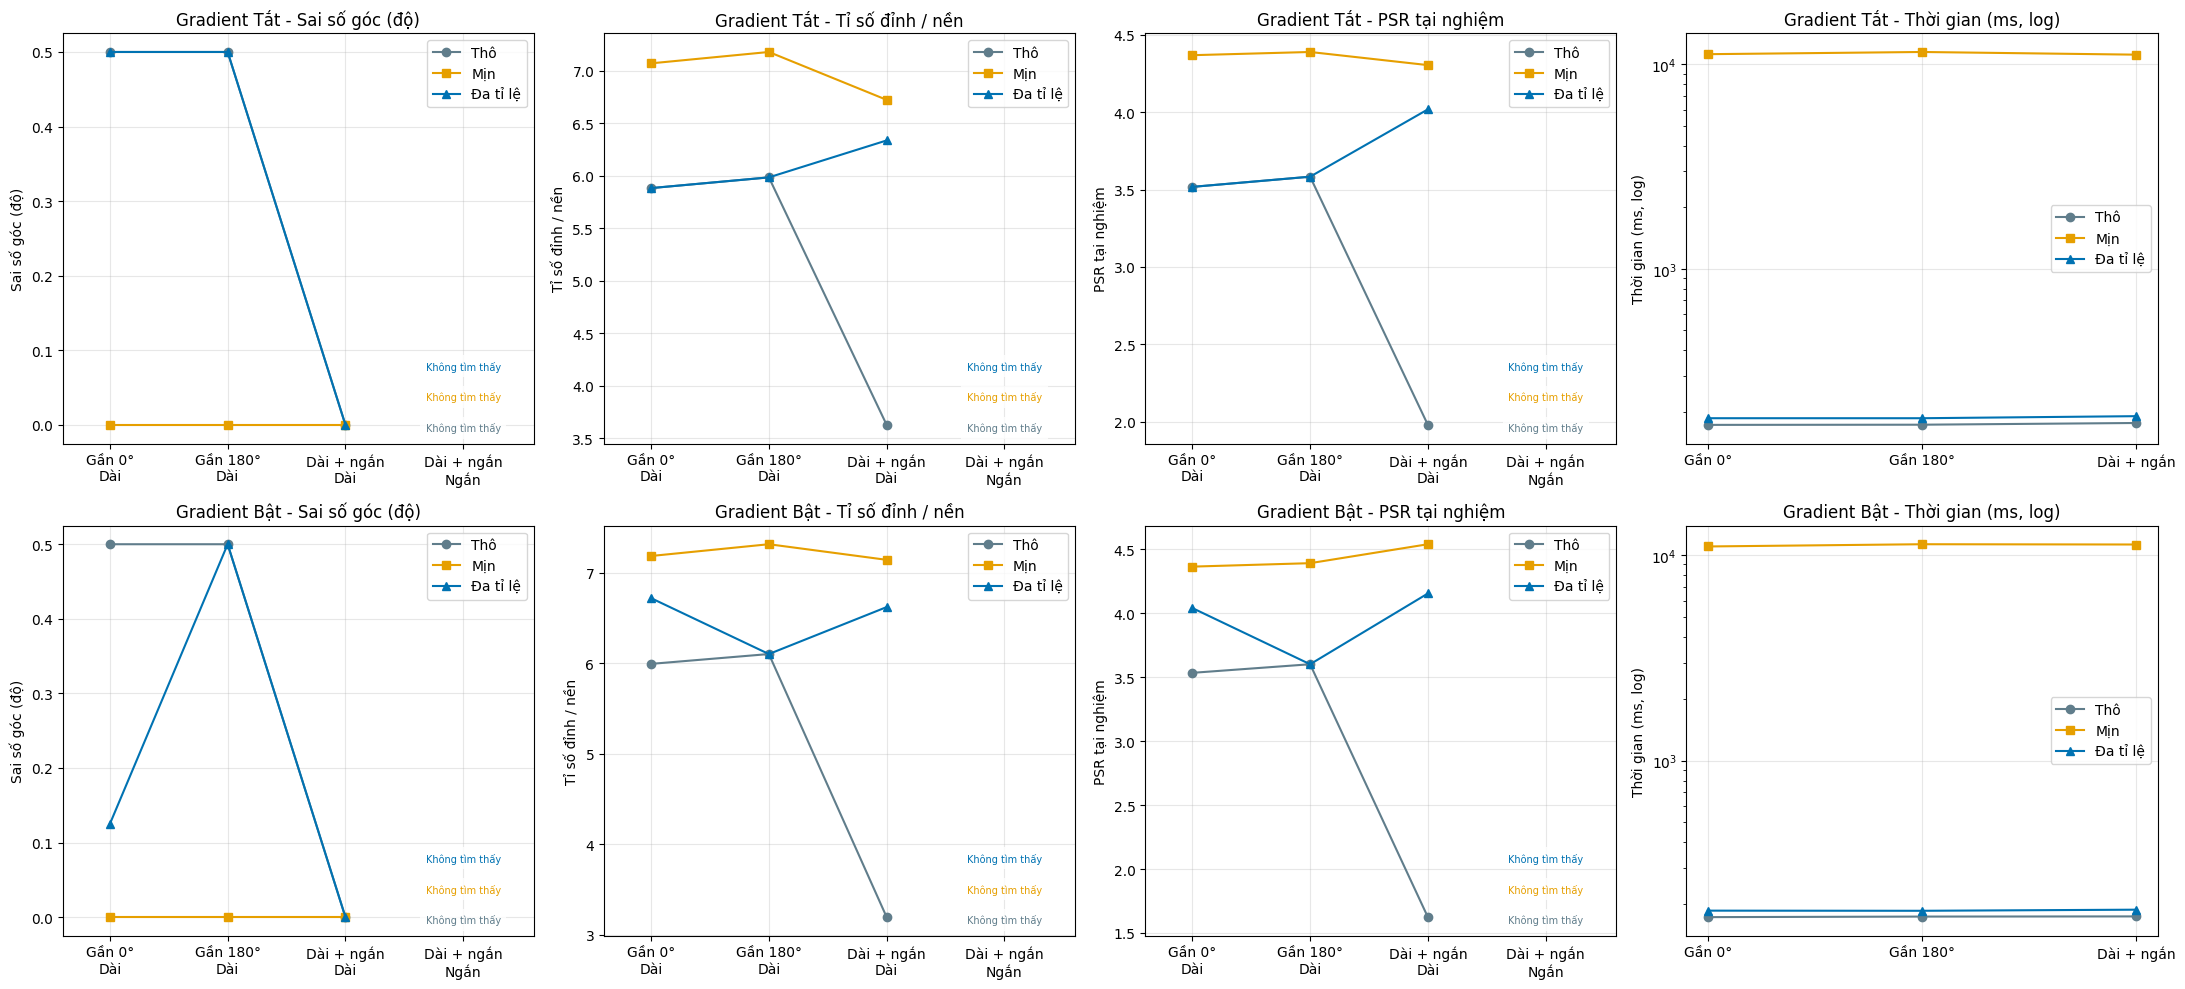

In [26]:
v3_labels = [(c['name'], target[0]) for c in v3_cases for target in c['truth']]
v3_colors = {'Thô': '#607d8b', 'Mịn': '#e69f00', 'Đa tỉ lệ': '#0072b2'}
v3_markers = {'Thô': 'o', 'Mịn': 's', 'Đa tỉ lệ': '^'}
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ri, mode in enumerate(V3_MODES):
    for mi, method in enumerate(V3_METHODS):
        selected = [next(r for r in v3_records if r['image'] == name
                         and r['target'] == target and r['method'] == method
                         and r['gradient'] == mode) for name, target in v3_labels]
        for ci, metric in enumerate(['angle_error', 'peak_ratio', 'psr']):
            ax = axes[ri, ci]
            ax.plot(range(len(selected)), [r[metric] for r in selected],
                    marker=v3_markers[method], linestyle='-',
                    label=method, color=v3_colors[method])
            for xi, row in enumerate(selected):
                if not row['found'] or not np.isfinite(row[metric]):
                    text = 'Không tìm thấy' if not row['found'] else 'Không xác định'
                    ax.text(xi, 0.03 + 0.075 * mi, text, transform=ax.get_xaxis_transform(),
                            ha='center', fontsize=7, color=v3_colors[method],
                            bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
        ts = [np.median(v3_runs[(c['name'], mode, method)]['times']) for c in v3_cases]
        axes[ri, 3].plot(range(len(ts)), ts, marker=v3_markers[method],
                         label=method, color=v3_colors[method])
    for ci in range(3):
        axes[ri, ci].set_xticks(range(len(v3_labels)),
                              [f'{name}\n{target}' for name, target in v3_labels])
        axes[ri, ci].set_xlim(-0.4, len(v3_labels) - 0.4)
    axes[ri, 3].set_xticks(range(len(v3_cases)), [c['name'] for c in v3_cases])
    axes[ri, 3].set_yscale('log')
    for ci, ylabel in enumerate(['Sai số góc (độ)', 'Tỉ số đỉnh / nền',
                                  'PSR tại nghiệm', 'Thời gian (ms, log)']):
        axes[ri, ci].set_title(f'Gradient {mode} - {ylabel}')
        axes[ri, ci].set_ylabel(ylabel)
        axes[ri, ci].grid(alpha=0.3)
        axes[ri, ci].legend()
plt.tight_layout()
plt.show()


###  Kiểm tra trực quan đoạn dài và đoạn ngắn

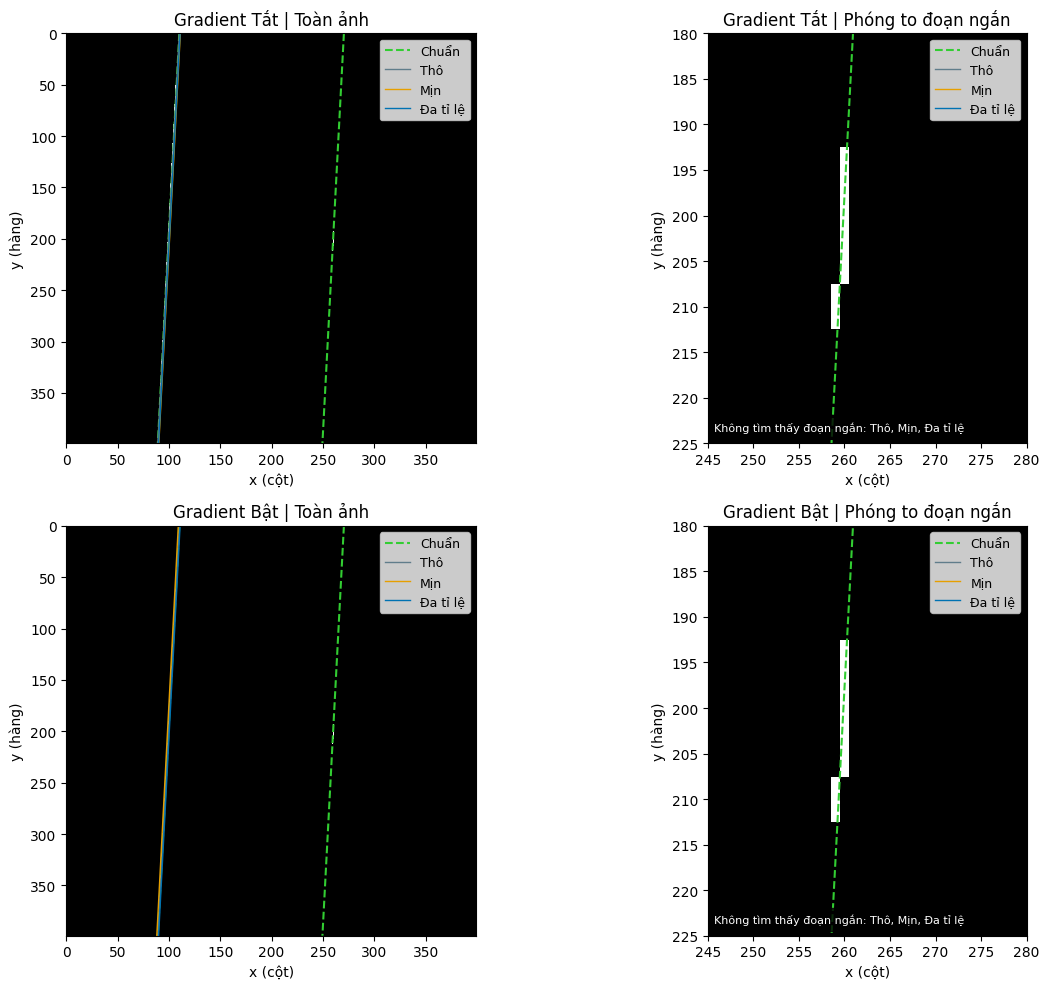

In [27]:
case = v3_cases[2]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
y = np.arange(case['image'].shape[0])
for ri, mode in enumerate(V3_MODES):
    for ci in range(2):
        ax = axes[ri, ci]
        ax.imshow(case['image'], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        for ti, (_, rho, td, _) in enumerate(case['truth']):
            t = np.deg2rad(td)
            ax.plot((rho - y * np.sin(t)) / np.cos(t), y,
                    '--', color='limegreen', linewidth=1.5,
                    label='Chuẩn' if ti == 0 else None)
        for method in V3_METHODS:
            run = v3_runs[(case['name'], mode, method)]
            labeled = False
            for ti, pi in run['matches'].items():
                rho, t = run['peaks'][pi]
                ax.plot((rho - y * np.sin(t)) / np.cos(t), y,
                        color=v3_colors[method], linewidth=1,
                        label=method if not labeled else None)
                labeled = True
        if ci == 0:
            ax.set_xlim(0, 399)
            ax.set_ylim(399, 0)
        else:
            ax.set_xlim(245, 280)
            ax.set_ylim(225, 180)
        ax.set_title(f'Gradient {mode} | ' + ('Toàn ảnh' if ci == 0 else 'Phóng to đoạn ngắn'))
        ax.set_xlabel('x (cột)')
        ax.set_ylabel('y (hàng)')
        ax.legend(fontsize=9)
        if ci == 1:
            missing = [method for method in V3_METHODS
                       if 1 not in v3_runs[(case['name'], mode, method)]['matches']]
            if missing:
                ax.text(0.02, 0.03, 'Không tìm thấy đoạn ngắn: ' + ', '.join(missing),
                        transform=ax.transAxes, color='white', fontsize=8,
                        bbox=dict(facecolor='black', alpha=0.8))
plt.tight_layout()
plt.show()

###  Nhận xét tự động từ kết quả

In [28]:
print('1. SO ĐA TỈ LỆ VỚI THÔ VÀ MỊN')
for name, target in v3_labels:
    for mode in V3_MODES:
        rr = {r['method']: r for r in v3_records if r['image'] == name
              and r['target'] == target and r['gradient'] == mode}
        c, f, m = [rr[key] for key in V3_METHODS]
        print(f'\n{name}, đoạn {target}, gradient {mode}:')
        for method in V3_METHODS:
            r = rr[method]
            if r['found']:
                print(f"  {method}: sai số góc {r['angle_error']:.3f}°, "
                      f"PSR {v3_fmt(r['psr'])}, {r['time_ms']:.1f} ms.")
            else:
                print(f'  {method}: KHÔNG TÌM THẤY trong cửa sổ ghép đã công bố.')
        if c['found'] and m['found']:
            print(f"  Đa tỉ lệ trừ thô: {m['angle_error'] - c['angle_error']:+.3f}° sai số.")
        print(f"  Tốc độ mịn/đa tỉ lệ: {f['time_ms'] / m['time_ms']:.2f} lần "
              '(>1: đa tỉ lệ nhanh hơn).')

print('\n2. ẢNH HƯỞNG BẬT GRADIENT: thời gian tắt/bật (>1: bật nhanh hơn)')
for case in v3_cases:
    for method in V3_METHODS:
        off = np.median(v3_runs[(case['name'], 'Tắt', method)]['times'])
        on = np.median(v3_runs[(case['name'], 'Bật', method)]['times'])
        print(f"{case['name']:12s} | {method:9s}: {off / on:.3f} lần")
        for target, *_ in case['truth']:
            rr = {r['gradient']: r for r in v3_records if r['image'] == case['name']
                  and r['target'] == target and r['method'] == method}
            if all(r['found'] for r in rr.values()):
                print(f"  {target}: sai số bật−tắt = "
                      f"{rr['Bật']['angle_error'] - rr['Tắt']['angle_error']:+.3f}°; "
                      f"PSR tắt/bật = {v3_fmt(rr['Tắt']['psr'])}/{v3_fmt(rr['Bật']['psr'])}.")
            else:
                print(f"  {target}: tìm thấy tắt/bật = {rr['Tắt']['found']}/{rr['Bật']['found']}.")

print('\n3. TỰ KIỂM TRA')
assert len(v3_runs) == 18 and len(v3_records) == 24
assert all(len(r['times']) == V3_REPEATS for r in v3_runs.values())
assert all(np.isfinite(r['times']).all() and min(r['times']) > 0 for r in v3_runs.values())
assert all(0 <= t < np.pi for r in v3_runs.values() for _, t in r['peaks'])
for method in V3_METHODS:
    rs = [r for r in v3_records if r['method'] == method]
    print(f'{method}: tìm thấy {sum(r["found"] for r in rs)}/{len(rs)} đường chuẩn qua 2 chế độ.')
print('Đủ 3 phương pháp × 2 chế độ × 3 ảnh; đủ sai số góc, PSR và thời gian.')
print('NaN/— ở kết quả không tìm thấy hoặc PSR không xác định không được đổi thành 0.')

1. SO ĐA TỈ LỆ VỚI THÔ VÀ MỊN

Gần 0°, đoạn Dài, gradient Tắt:
  Thô: sai số góc 0.500°, PSR 3.517, 172.2 ms.
  Mịn: sai số góc 0.000°, PSR 4.368, 11226.7 ms.
  Đa tỉ lệ: sai số góc 0.500°, PSR 3.517, 185.6 ms.
  Đa tỉ lệ trừ thô: +0.000° sai số.
  Tốc độ mịn/đa tỉ lệ: 60.49 lần (>1: đa tỉ lệ nhanh hơn).

Gần 0°, đoạn Dài, gradient Bật:
  Thô: sai số góc 0.500°, PSR 3.534, 173.2 ms.
  Mịn: sai số góc 0.000°, PSR 4.365, 11005.1 ms.
  Đa tỉ lệ: sai số góc 0.125°, PSR 4.041, 186.3 ms.
  Đa tỉ lệ trừ thô: -0.375° sai số.
  Tốc độ mịn/đa tỉ lệ: 59.08 lần (>1: đa tỉ lệ nhanh hơn).

Gần 180°, đoạn Dài, gradient Tắt:
  Thô: sai số góc 0.500°, PSR 3.583, 172.5 ms.
  Mịn: sai số góc 0.000°, PSR 4.389, 11509.2 ms.
  Đa tỉ lệ: sai số góc 0.500°, PSR 3.583, 185.6 ms.
  Đa tỉ lệ trừ thô: +0.000° sai số.
  Tốc độ mịn/đa tỉ lệ: 62.02 lần (>1: đa tỉ lệ nhanh hơn).

Gần 180°, đoạn Dài, gradient Bật:
  Thô: sai số góc 0.500°, PSR 3.601, 174.3 ms.
  Mịn: sai số góc 0.000°, PSR 4.392, 11283.9 ms.
  Đa tỉ l

In [29]:
v3_short_trials = []
case = v3_cases[2]
trial_configs = [(10, 6.0, 3.0), (30, 6.0, 3.0), (30, 12.0, 6.0)]
print('THỬ THÊM SỐ ĐỈNH / NMS - cùng ảnh dài + ngắn, không dùng đáp án để tìm đỉnh')
print('Phương pháp | Gradient | Số đỉnh | NMS px/độ | Tìm dài/ngắn | Sai số góc đoạn ngắn')
for mode in V3_MODES:
    grad = case['grad'] if mode == 'Bật' else None
    for method in ['Thô', 'Đa tỉ lệ']:
        for n_peaks, nr, nt in trial_configs:
            if (n_peaks, nr, nt) == trial_configs[0]:
                peaks = v3_runs[(case['name'], mode, method)]['peaks']
            else:
                peaks = v3_detect(case['edges'], grad, method,
                                  n_peaks=n_peaks, nms_rho=nr, nms_theta=nt)
            matches = v3_match(peaks, case['truth'])
            error = np.nan
            if 1 in matches:
                error = v3_angle_error(3, np.rad2deg(peaks[matches[1]][1]))
            v3_short_trials.append(dict(method=method, gradient=mode,
                n_peaks=n_peaks, nms_rho=nr, nms_theta=nt,
                long_found=0 in matches, short_found=1 in matches, short_angle_error=error))
            print(f'{method:9s} | {mode:3s} | {n_peaks:2d} | {nr:g}/{nt:g} | '
                  f'{0 in matches}/{1 in matches} | {v3_fmt(error)}')
print('Thử thêm chỉ áp dụng thô và đa tỉ lệ; bảng chính vẫn giữ nguyên 18 cấu hình.')


THỬ THÊM SỐ ĐỈNH / NMS - cùng ảnh dài + ngắn, không dùng đáp án để tìm đỉnh
Phương pháp | Gradient | Số đỉnh | NMS px/độ | Tìm dài/ngắn | Sai số góc đoạn ngắn
Thô       | Tắt | 10 | 6/3 | True/False | —
Thô       | Tắt | 30 | 6/3 | True/True | 1.000
Thô       | Tắt | 30 | 12/6 | True/True | 0.000
Đa tỉ lệ  | Tắt | 10 | 6/3 | True/False | —
Đa tỉ lệ  | Tắt | 30 | 6/3 | True/True | 1.000
Đa tỉ lệ  | Tắt | 30 | 12/6 | True/True | 0.125
Thô       | Bật | 10 | 6/3 | True/False | —
Thô       | Bật | 30 | 6/3 | True/True | 2.000
Thô       | Bật | 30 | 12/6 | True/True | 1.000
Đa tỉ lệ  | Bật | 10 | 6/3 | True/False | —
Đa tỉ lệ  | Bật | 30 | 6/3 | True/True | 0.750
Đa tỉ lệ  | Bật | 30 | 12/6 | True/True | 0.750
Thử thêm chỉ áp dụng thô và đa tỉ lệ; bảng chính vẫn giữ nguyên 18 cấu hình.
